<a href="https://colab.research.google.com/github/dahlia1384/ENGR418_TeamProject8/blob/main/UCI_HAR_Dataset_Project_Updated_13_10_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Step 0: Linking Google Drive ('cuz I'm an Idiot)**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

# **1. Preliminary Analysis of the UCI-HAR 2012 Dataset**

The preliminary analysis should answer four practical questions before modelling:
1. Is the dataset loaded correctly?
2. Are the activity classes and participants adequately represented?
3. How redundant are the 561 features?
4. Does the data suggest that dimensionality reduction is justified?

Its purpose is to verify the data and justify the modelling design, not to select the configuration that performs best on the official test set. We are using the official training set only for these decisions.


**Important Note:** Gemini did help me code this, mainly because syntax can be incredibly annoying, *especially* in Python and with pathing.


# **1.1. Loading and Assembling the Training Data**

The official UCI-HAR folder contains separate files for features, activity labels, and participant identifiers.

In [ ]:
### Some Inportant Imports Needed
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler as stsc
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedGroupKFold as sgk
from sklearn.pipeline import Pipeline as ppl
from sklearn.linear_model import LogisticRegression as logreg
from sklearn.model_selection import GridSearchCV as gsCV

DATA_DIR = Path("/content/drive/MyDrive/human+activity+recognition+using+smartphones/UCI HAR Dataset")

# Feature Descriptions of the Dataset
features = pd.read_csv(DATA_DIR / "features.txt", sep=r"\s+", header=None, names=["feature_id", "feature_name"])

# Adding the feature number becomes some UCI feature names are duplicated
feature_names = [f"f{row.feature_id:03d}_{row.feature_name}" for row in features.itertuples()]

# Training Data
X_train = pd.read_csv(DATA_DIR / "train/X_train.txt", sep=r"\s+", header=None, names=feature_names)
y_train = pd.read_csv(DATA_DIR / "train/y_train.txt", sep=r"\s+", header=None, names=["activity_id"])["activity_id"]
subject_train = pd.read_csv(DATA_DIR / "train/subject_train.txt", sep=r"\s+", header=None, names=["subject_id"])["subject_id"]

# Acitvity_name lookups
activity_labels = pd.read_csv(DATA_DIR / "activity_labels.txt", sep=r"\s+", header=None, names=["activity_id", "activity_name"])
activity_map = dict(zip(activity_labels.activity_id, activity_labels.activity_name))

y_names = y_train.map(activity_map)

# Confirming the expected dimensions
print(X_train.shape)                  # Should have 7,352 datapoints with 561 features
print(y_train.shape[0])               # Should have 7,352 activity labels
print(y_train.nunique())              # Should have 6 unique activity labels
print(subject_train.shape[0])         # Should have 7,352 unique datapoints
print(subject_train.nunique())        # Should have 21 participants

# Added security feature. Adding assertions to detect an incorrectly loaded file.
assert X_train.shape == (7352, 561)
assert y_train.shape[0] == 7352
assert y_train.nunique() == 6
assert subject_train.shape[0] == 7352
assert subject_train.nunique() == 21

(7352, 561)
7352
6
7352
21


The official UCI-HAR training set was loaded successfully. It contained 7,352 observations, each represented by 561 sensor-derived features. Every observation had a corresponding activity label and participant identifier. The training data included six activity classes collected from 21 unique participants.

# **1.2. Checking Data Integrity**


In [ ]:
# Checking for missing values, infinite values, invalid labels, and duplicated observations. Verifying that every feature is numeric.

print("Missing values:", X_train.isna().sum().sum())                  # Should be 0
print("Infinite values:", np.isinf(X_train.to_numpy()).sum())         # Should be 0
print("Duplicate feature rows:", X_train.duplicated().sum())          # Should be 0
print("Activity codes:", sorted(y_train.unique()))                    # Should look like [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
print("Subjects:", sorted(subject_train.unique()))                    # Should look like [np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]

non_numeric = X_train.select_dtypes(exclude=np.number).columns
print("Non-numeric columns:", list(non_numeric))                      # Should be empty []

### Do not automatically delete duplicated rows. Because the data consist of windowed sensor measurements, identical or nearly identical observations may be legitimate. Reporting their number first and investigate their labels and participants,
duplicate_mask = X_train.duplicated(keep=False)
duplicate_check = pd.DataFrame({"activity": y_names[duplicate_mask], "subject": subject_train[duplicate_mask]})
print(duplicate_check.head())

Missing values: 0
Infinite values: 0
Duplicate feature rows: 0
Activity codes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Subjects: [np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]
Non-numeric columns: []
Empty DataFrame
Columns: [activity, subject]
Index: []


No immediate data-integrity issues were identified in the training dataset. The feature matrix contained no missing or infinite values, no non-numeric variables, and no exact duplicate observations. All six expected activity codes were present, and the 21 unique subject identifiers were consistent with the official participant-separated training partition.

# **1.3. Examining the Activity Class Representation**

                    count    percent
activity_id                         
LAYING               1407  19.137650
STANDING             1374  18.688792
SITTING              1286  17.491839
WALKING              1226  16.675734
WALKING_UPSTAIRS     1073  14.594668
WALKING_DOWNSTAIRS    986  13.411317


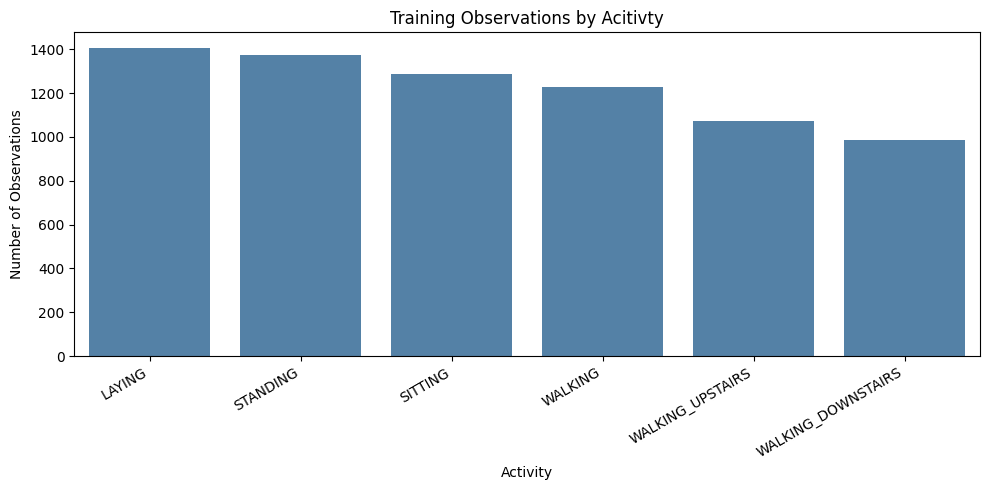

Imbalance ratio/Largest-to-smallest ratio: 1.4269776876267748


In [ ]:
# Determining how many observations belong to each activity.

class_counts = y_names.value_counts()
class_percent = y_names.value_counts(normalize = True).mul(100)
class_summary = pd.DataFrame({"count": class_counts, "percent": class_percent})
print(class_summary)


plt.figure(figsize=(10, 5))
sns.countplot(x = y_names, order = class_counts.index, color = "steelblue")
plt.xticks(rotation = 30, ha = "right")
plt.xlabel("Activity")
plt.ylabel("Number of Observations")
plt.title("Training Observations by Acitivty")
plt.tight_layout()
plt.show()

# Imbalance ratios
# A large imbalance will justify a macro-F1 addition to accuracy calculations.
imbalance_ratio = class_counts.max()/class_counts.min()
print("Imbalance ratio/Largest-to-smallest ratio:", imbalance_ratio)

The training data exhibited mild class imbalance. LAYING was the most represented activity with 1,407 observations (19.14%), while WALKING_DOWNSTAIRS was the least represented with 986 observations (13.41%). The resulting largest-to-smallest class ratio was approximately 1.43:1. Although the imbalance was not severe enough to require resampling, macro-averaged F1-score and class-specific performance measures will be reported alongside accuracy to ensure that performance on the smaller classes is adequately represented.

# **1.4.A. Examining Each Representation by Participant**

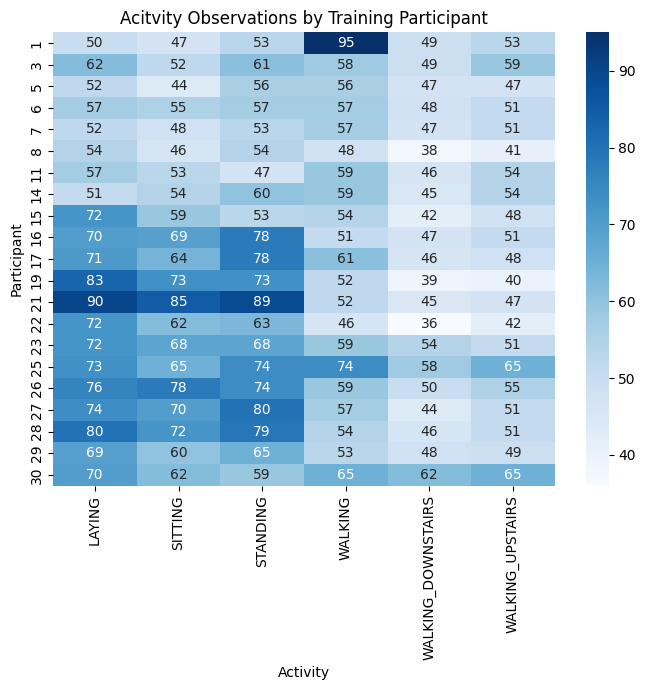

In [ ]:
# The analysis should confirm the following:
#     1. Whether every participant performed every activity;
#     2. Whether some participants contributed substantially more observations;
#     3. Whether particular activites are underrepresented for certain participants.
# The results can support the decision to use participant-grouped cross-validation.
# If observations were randomly divided into folds, measurements from the same person would appear in both training and test data.

subject_activity = pd.crosstab(subject_train, y_names)
#print(subject_activity)

plt.figure(figsize=(7, 7))
sns.heatmap(subject_activity, cmap = "Blues", annot = True, fmt = "d")
plt.xlabel("Activity")
plt.ylabel("Participant")
plt.title("Acitvity Observations by Training Participant")
plt.tight_layout()
plt.show()

Participant contributions were not uniformly distributed across activities. Individual participant–activity combinations contained between 36 and 95 observations, with some participants contributing substantially more observations to particular activities. For example, Participant 1 contributed 95 WALKING observations, while Participant 21 contributed 85–90 observations to the three stationary activities. Nevertheless, all 21 training participants were represented in all six activity classes, and no participant–activity combinations were missing. The observed heterogeneity reinforces the use of participant-grouped cross-validation to prevent observations from the same individual from appearing in both training and validation subsets.

# **1.4.B. Cross-Validation**



Number of folds: 5

Fold 1
Training participants: [np.int64(1), np.int64(3), np.int64(6), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(23), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]
Validation participants: [np.int64(5), np.int64(7), np.int64(22), np.int64(25)]
Participant overlap: []

Fold 2
Training participants: [np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(22), np.int64(23), np.int64(25), np.int64(26), np.int64(27), np.int64(29), np.int64(30)]
Validation participants: [np.int64(1), np.int64(19), np.int64(21), np.int64(28)]
Participant overlap: []

Fold 3
Training participants: [np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(25), np.int64(26), np.int64(28), np.i

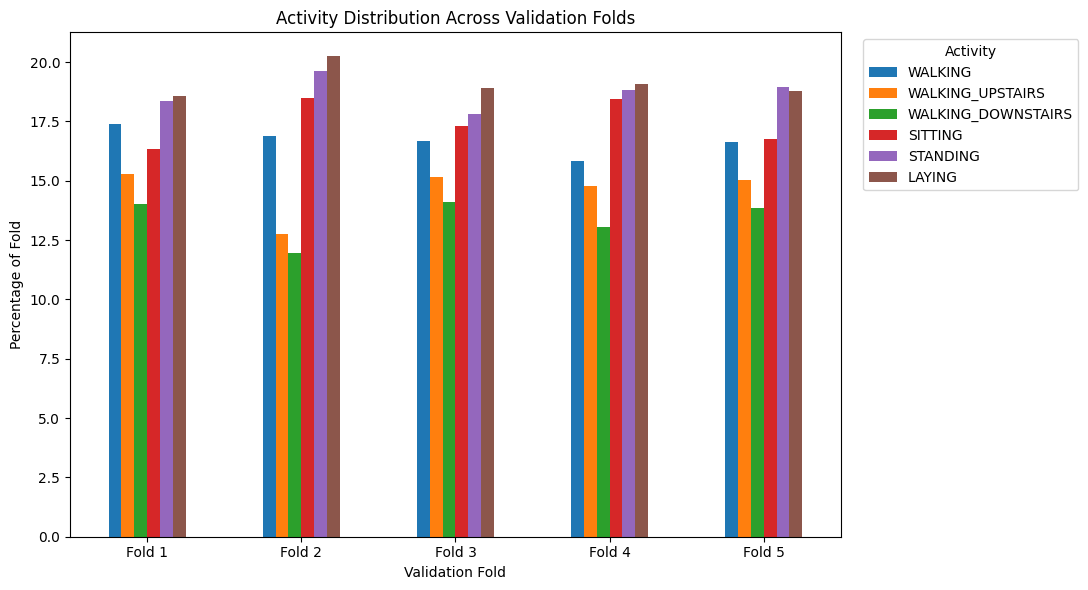

All six activities in every validation fold: PASS
Every participant validated exactly once: PASS
No participant overlap: PASS

Conclusion: The folds satisfy the essential requirements for participant-grouped cross-validation.
Best parameters: {'classifier__C': 1}
Best cross-validation macro-F1: 0.9264
 fold  training_macro_f1  validation_macro_f1  validation_accuracy
    1             0.9989               0.9110               0.9142
    2             0.9984               0.9350               0.9312
    3             0.9967               0.9692               0.9693
    4             0.9989               0.8667               0.8687
    5             0.9969               0.9501               0.9521

Mean validation macro-F1: 0.9264
SD validation macro-F1: 0.0396
Minimum validation macro-F1: 0.8667
Maximum validation macro-F1: 0.9692
Mean training-validation gap: 0.0716
 param_classifier__C  mean_train_macro_f1  mean_test_macro_f1  std_test_macro_f1  mean_test_accuracy  rank_test_macro_f1 

In [ ]:
# Resetting the indices ensures that positional indices returned by scikit-learn correspond correctly to all three datasets.

X_cv = X_train.reset_index(drop=True)
y_cv = y_train.reset_index(drop=True)
groups_cv = subject_train.reset_index(drop=True)

# Convert numeric activity codes to names for readable output
y_name_cv = y_cv.map(activity_map)

activity_order = [activity_map[activity_id] for activity_id in sorted(activity_map)]

assert len(X_cv) == len(y_cv) == len(groups_cv)
assert y_name_cv.notna().all()

# Creating the participant-grouped folds
cv = sgk(n_splits=5, shuffle=True, random_state=42)

cv_splits = list(cv.split(X_cv, y_cv, groups=groups_cv))

print("Number of folds:", len(cv_splits))

# Check participant separation and fold sizes

summary_rows = []
validation_subjects_all = []
fold_assignments = {}

for fold, (train_index, validation_index) in enumerate(cv_splits, start=1):
    train_subjects = sorted(groups_cv.iloc[train_index].unique())
    validation_subjects = sorted(groups_cv.iloc[validation_index].unique())
    overlap = set(train_subjects).intersection(validation_subjects)

    validation_subjects_all.extend(validation_subjects)

    for subject in validation_subjects:
        fold_assignments[int(subject)] = fold

    summary_rows.append({
        "fold": fold,
        "training_rows": len(train_index),
        "validation_rows": len(validation_index),
        "training_subjects": len(train_subjects),
        "validation_subjects": len(validation_subjects),
        "subject_overlap": len(overlap),
        "validation_classes":
            y_cv.iloc[validation_index].nunique()
    })

    print(f"\nFold {fold}")
    print("Training participants:", train_subjects)
    print("Validation participants:", validation_subjects)
    print("Participant overlap:", sorted(overlap))

summary_df = pd.DataFrame(summary_rows)

print("\nCross-validation summary")
print(summary_df.to_string(index=False))

# Verifying that every participant is validated once

validation_frequency = (pd.Series(validation_subjects_all, name="subject_id").value_counts().sort_index())

print("\nNumber of validation appearances per participant")
print(validation_frequency.to_string())

print("\nParticipant-to-fold assignment")
for subject, fold in sorted(fold_assignments.items()):
    print(f"Participant {subject}: Fold {fold}")

assert len(validation_subjects_all) == groups_cv.nunique()
assert set(validation_subjects_all) == set(groups_cv.unique())
assert validation_frequency.eq(1).all()
assert summary_df["subject_overlap"].eq(0).all()
assert summary_df["validation_classes"].eq(6).all()

# Printing activity counts in every validation fold

fold_counts = {}

for fold, (_, validation_index) in enumerate(cv_splits,start=1):
    counts = (y_name_cv.iloc[validation_index].value_counts().reindex(activity_order, fill_value=0))
    fold_counts[f"Fold {fold}"] = counts

fold_count_df = pd.DataFrame(fold_counts)

print("\nActivity counts by validation fold")
print(fold_count_df.to_string())

# Printing activity percentages in every validation fold

fold_percent_df = (fold_count_df.divide(fold_count_df.sum(axis=0), axis=1).multiply(100))

print("\nActivity percentages by validation fold")
print(fold_percent_df.round(2).to_string())

overall_percentage = (y_name_cv.value_counts(normalize=True).reindex(activity_order).multiply(100))

comparison_df = fold_percent_df.copy()
comparison_df.insert(0, "Overall training set", overall_percentage)

print("\nOverall and fold-specific percentages")
print(comparison_df.round(2).to_string())

# Quantifying deviations from the whole distribution

deviation_df = fold_percent_df.subtract(overall_percentage, axis=0)

absolute_deviation_df = deviation_df.abs()

print("\nPercentage-point deviation from overall distribution")
print(absolute_deviation_df.round(2).to_string())

maximum_deviation_by_fold = (absolute_deviation_df.max(axis=0))

print("\nMaximum absolute deviation in each fold")
print(maximum_deviation_by_fold.round(2).to_string())

print("\nLargest deviation across all folds:", round(absolute_deviation_df.to_numpy().max(), 2), "percentage points")

# Visualizing the fold distributions

fold_percent_df.T.plot(kind="bar", figsize=(11, 6))

plt.xlabel("Validation Fold")
plt.ylabel("Percentage of Fold")
plt.title("Activity Distribution Across Validation Folds")
plt.xticks(rotation=0)
plt.legend(title="Activity", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Diagnostic Summary

zero_overlap = summary_df["subject_overlap"].eq(0).all()
all_classes_present = (
    summary_df["validation_classes"].eq(6).all()
)
each_subject_once = validation_frequency.eq(1).all()

print("All six activities in every validation fold:", "PASS" if all_classes_present else "FAIL")

print("Every participant validated exactly once:", "PASS" if each_subject_once else "FAIL")

print("No participant overlap:", "PASS" if zero_overlap else "FAIL")

if zero_overlap and all_classes_present and each_subject_once:
    print("\nConclusion: The folds satisfy the essential requirements for participant-grouped cross-validation.")
else:
    print("\nConclusion: The fold construction requires further investigation.")

# We are going to use the same folds during model tuning.

pipeline = ppl([("scaler", stsc()),("classifier",logreg(max_iter=5000))])

parameter_grid = {"classifier__C": [0.1, 1, 10]}

search = gsCV(estimator=pipeline, param_grid=parameter_grid,
    scoring={
        "macro_f1": "f1_macro",
        "accuracy": "accuracy"
    }, refit="macro_f1", cv=cv_splits, n_jobs=-1, return_train_score=True)

search.fit(X_cv, y_cv)

print("Best parameters:", search.best_params_)
print("Best cross-validation macro-F1:", round(search.best_score_, 4))

best_index = search.best_index_

validation_f1 = np.array([search.cv_results_[f"split{fold}_test_macro_f1"][best_index] for fold in range(5)])

training_f1 = np.array([search.cv_results_[f"split{fold}_train_macro_f1"][best_index] for fold in range(5)])

validation_accuracy = np.array([search.cv_results_[f"split{fold}_test_accuracy"][best_index] for fold in range(5)])

fold_performance = pd.DataFrame({
    "fold": range(1, 6),
    "training_macro_f1": training_f1,
    "validation_macro_f1": validation_f1,
    "validation_accuracy": validation_accuracy
})

print(fold_performance.round(4).to_string(index=False))

print("\nMean validation macro-F1:", round(validation_f1.mean(), 4))
print("SD validation macro-F1:", round(validation_f1.std(ddof=1), 4))
print("Minimum validation macro-F1:", round(validation_f1.min(), 4))
print("Maximum validation macro-F1:", round(validation_f1.max(), 4))
print("Mean training-validation gap:", round(training_f1.mean() - validation_f1.mean(), 4))

# Confirming C = 1 with other regularization strengths

grid_results = pd.DataFrame(search.cv_results_)

comparison = grid_results[[
    "param_classifier__C",
    "mean_train_macro_f1",
    "mean_test_macro_f1",
    "std_test_macro_f1",
    "mean_test_accuracy",
    "rank_test_macro_f1"]].copy()

comparison["generalization_gap"] = (comparison["mean_train_macro_f1"] - comparison["mean_test_macro_f1"])

comparison = comparison.sort_values("rank_test_macro_f1")
print(comparison.round(4).to_string(index=False))

Five-fold stratified group cross-validation was constructed using participant identifiers as groups. Each validation fold contained four or five participants, and no participant appeared in both the training and validation portions of the same fold. All six activities were represented in every validation fold, and each of the 21 training participants appeared in validation exactly once. Activity proportions closely matched those of the complete training set, with a maximum absolute deviation of 1.84 percentage points. The folds were therefore considered suitable for leakage-resistant model selection. Using these folds, the preliminary full-feature Logistic Regression model selected \(C=1\) and achieved a mean cross-validation macro-F1 score of 0.9264.

The full-feature Logistic Regression model achieved a mean grouped cross-validation macro-F1 score of 0.9264, with a standard deviation of 0.0396. Fold-specific scores ranged from 0.8667 to 0.9692, demonstrating that performance varied depending on the participants withheld for validation. Training macro-F1 scores exceeded 0.996 in all folds, producing an average training–validation gap of 0.0716. This indicates that the model fitted the training participants extremely well but generalized less consistently to unseen individuals. Accuracy closely matched macro-F1 across all folds, suggesting that the observed variability was not primarily caused by class imbalance. These findings support investigating whether feature reduction and stronger regularization can improve cross-participant consistency while reducing model complexity.

# **1.5. Examining Feature Distributions and Variability**

                         count      mean       std       min       25%  \
f001_tBodyAcc-mean()-X  7352.0  0.274488  0.070261 -1.000000  0.262975   
f002_tBodyAcc-mean()-Y  7352.0 -0.017695  0.040811 -1.000000 -0.024863   
f003_tBodyAcc-mean()-Z  7352.0 -0.109141  0.056635 -1.000000 -0.120993   
f004_tBodyAcc-std()-X   7352.0 -0.605438  0.448734 -1.000000 -0.992754   
f005_tBodyAcc-std()-Y   7352.0 -0.510938  0.502645 -0.999873 -0.978129   

                             50%       75%       max  variance      skew  \
f001_tBodyAcc-mean()-X  0.277193  0.288461  1.000000  0.004937 -3.448322   
f002_tBodyAcc-mean()-Y -0.017219 -0.010783  1.000000  0.001665 -0.402995   
f003_tBodyAcc-mean()-Z -0.108676 -0.097794  1.000000  0.003208  1.784469   
f004_tBodyAcc-std()-X  -0.946196 -0.242813  1.000000  0.201363  0.677430   
f005_tBodyAcc-std()-Y  -0.851897 -0.034231  0.916238  0.252652  0.405892   

                          kurtosis     range  
f001_tBodyAcc-mean()-X   50.911391  2.000000  
f002

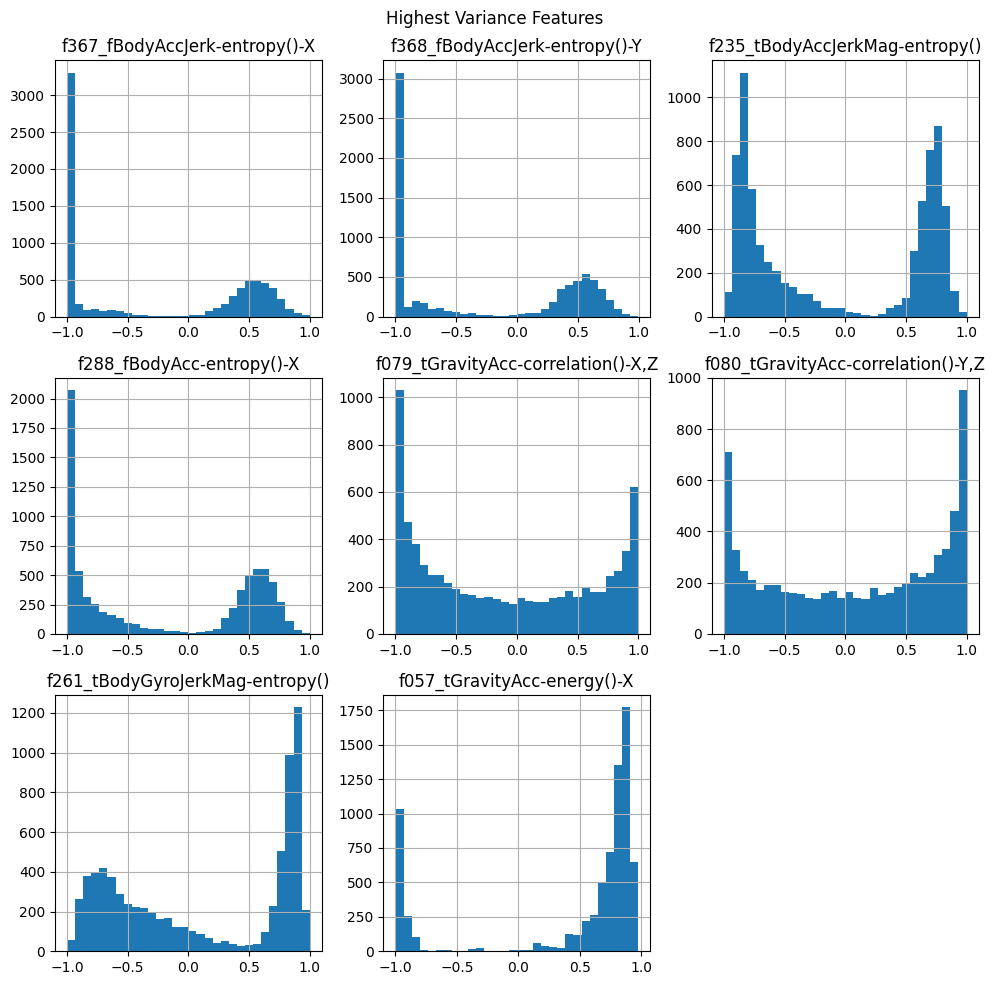

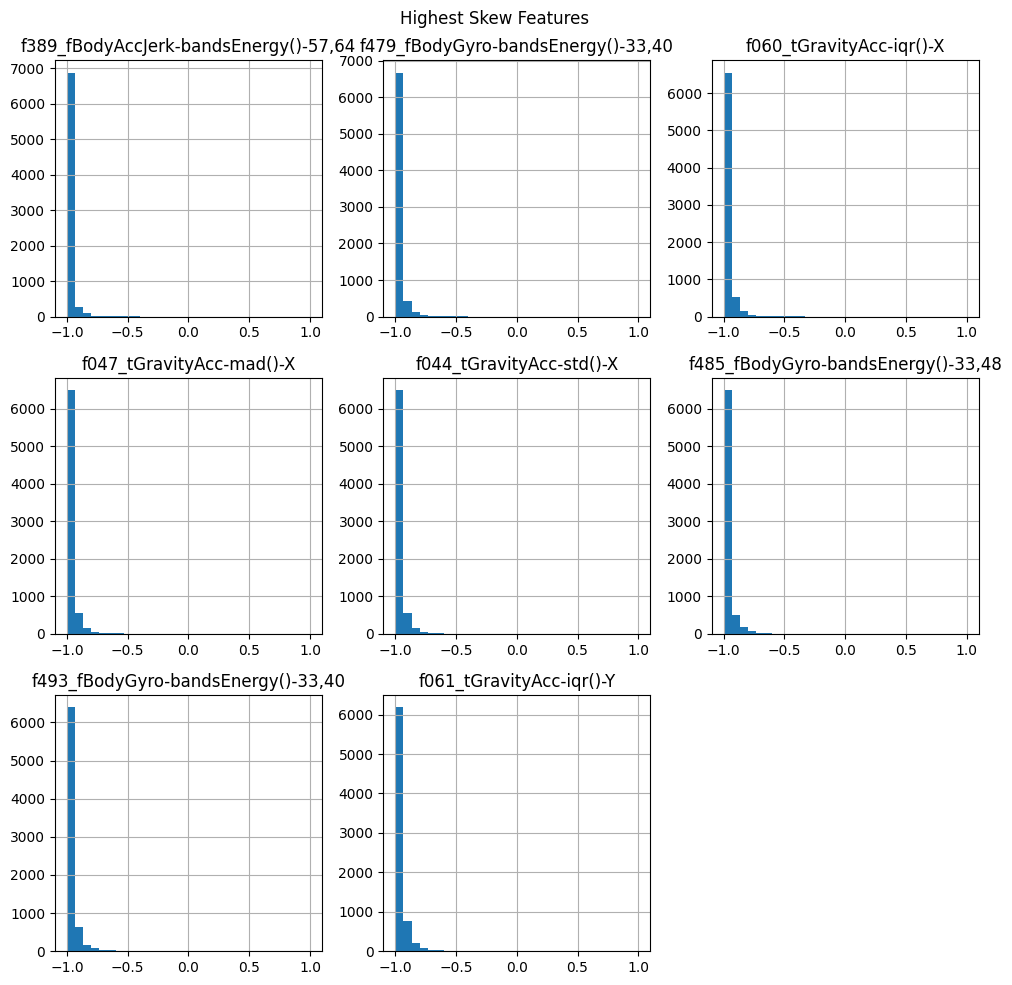

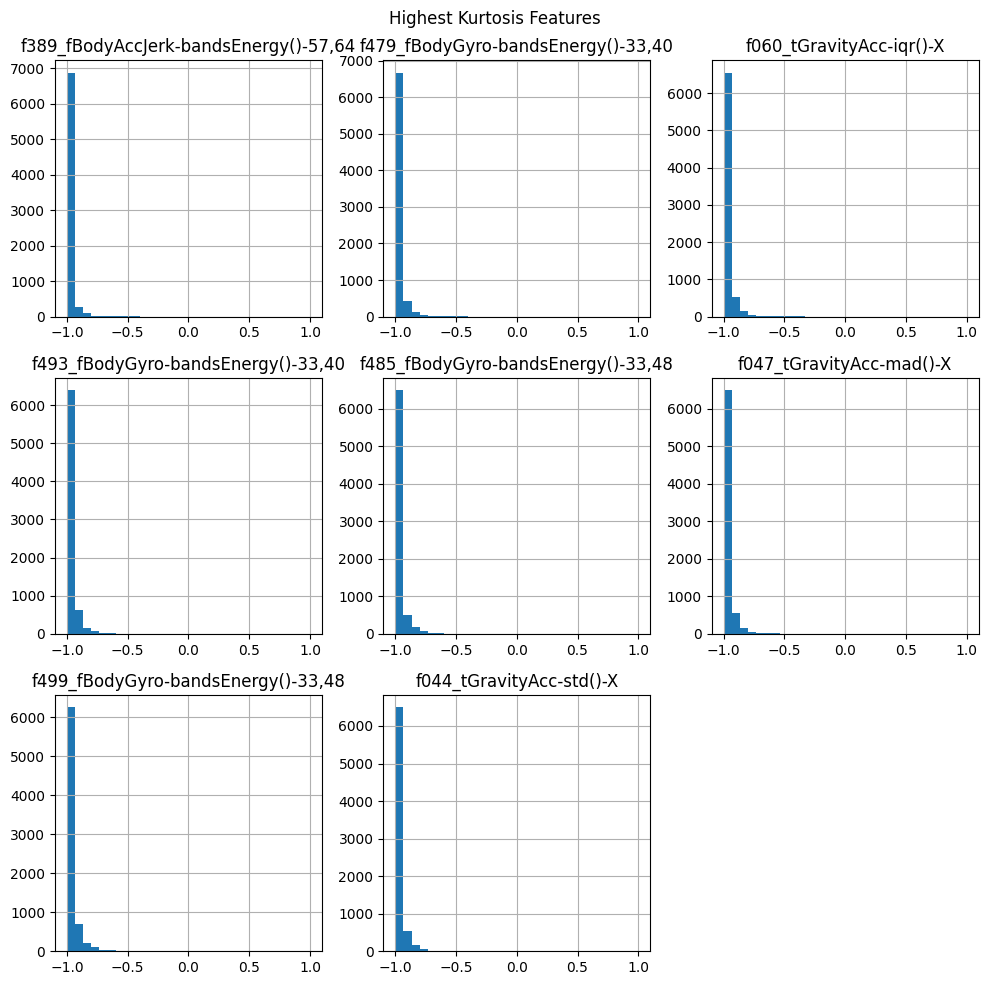

In [ ]:
# Descriptive Statistics:

feature_summary = X_train.describe().T
feature_summary["variance"] = X_train.var()
feature_summary["skew"] = X_train.skew()
feature_summary["kurtosis"] = X_train.kurtosis()
feature_summary["range"] = (feature_summary["max"] - feature_summary["min"])

print(feature_summary.head())

# Indentiying constant or nealry constant features:
const_features = feature_summary[feature_summary["variance"] == 0]
near_const_features = feature_summary[feature_summary["variance"] < 0.00001]

print("Constant Features: ", len(const_features))
print("Nearly Constant Features: ", len(near_const_features))

print("Overall Minimum: ", X_train.min().min())
print("Overall Maximum: ", X_train.max().max())

# The UCI-HAR features were normalized by the dataset developers and should fall ebtween -1 and 1.
# Values outside the expected range should be investigated.

# Not using all 561 features to make the distribution plot readable.
highest_variance = (X_train.var().sort_values(ascending=False).head(8).index)
highest_skew = (X_train.skew().sort_values(ascending=False).head(8).index)
highest_kurtosis = (X_train.kurtosis().sort_values(ascending=False).head(8).index)

X_train[highest_variance].hist(bins = 30, figsize = (10, 10))
plt.suptitle("Highest Variance Features")
plt.tight_layout()
plt.show()

X_train[highest_skew].hist(bins = 30, figsize = (10, 10))
plt.suptitle("Highest Skew Features")
plt.tight_layout()
plt.show()

X_train[highest_kurtosis].hist(bins = 30, figsize = (10, 10))
plt.suptitle("Highest Kurtosis Features")
plt.tight_layout()
plt.show()


All 561 input features exhibited nonzero variance, and no variables fell below the selected near-zero variance threshold of \(10^{-5}\). Feature values remained within the expected normalized interval of \([-1,1]\). Nevertheless, the variables differed substantially in variance and distributional shape. Several high-variance entropy, energy, and correlation features exhibited bimodal or boundary-concentrated distributions, while some variables displayed substantial skewness and excess kurtosis. These characteristics were not treated as data errors because the observations remained within the documented feature bounds and may represent meaningful differences among activities or participants. No features were removed during preliminary screening; redundancy and predictive usefulness will instead be evaluated through correlation analysis, PCA, feature selection, and participant-grouped cross-validation.

# **1.6. Quantifying Correlation and Feature Redundancy**

|r| > 0.9: 8206 feature pairs
|r| > 0.95: 2281 feature pairs
|r| > 0.99: 207 feature pairs
                               feature_1                        feature_2  \
156556      f529_fBodyBodyGyroMag-mean()      f534_fBodyBodyGyroMag-sma()   
155373           f503_fBodyAccMag-mean()           f508_fBodyAccMag-sma()   
105403          f240_tBodyGyroMag-mean()          f245_tBodyGyroMag-sma()   
109498      f253_tBodyGyroJerkMag-mean()      f258_tBodyGyroJerkMag-sma()   
95667        f211_tBodyAccMag-arCoeff()2   f224_tGravityAccMag-arCoeff()2   
95316        f210_tBodyAccMag-arCoeff()1   f223_tGravityAccMag-arCoeff()1   
92472             f202_tBodyAccMag-std()        f215_tGravityAccMag-std()   
92104            f201_tBodyAccMag-mean()           f206_tBodyAccMag-sma()   
156049   f516_fBodyBodyAccJerkMag-mean()   f521_fBodyBodyAccJerkMag-sma()   
156894  f542_fBodyBodyGyroJerkMag-mean()  f547_fBodyBodyGyroJerkMag-sma()   
92117            f201_tBodyAccMag-mean()        f219_tGravityA

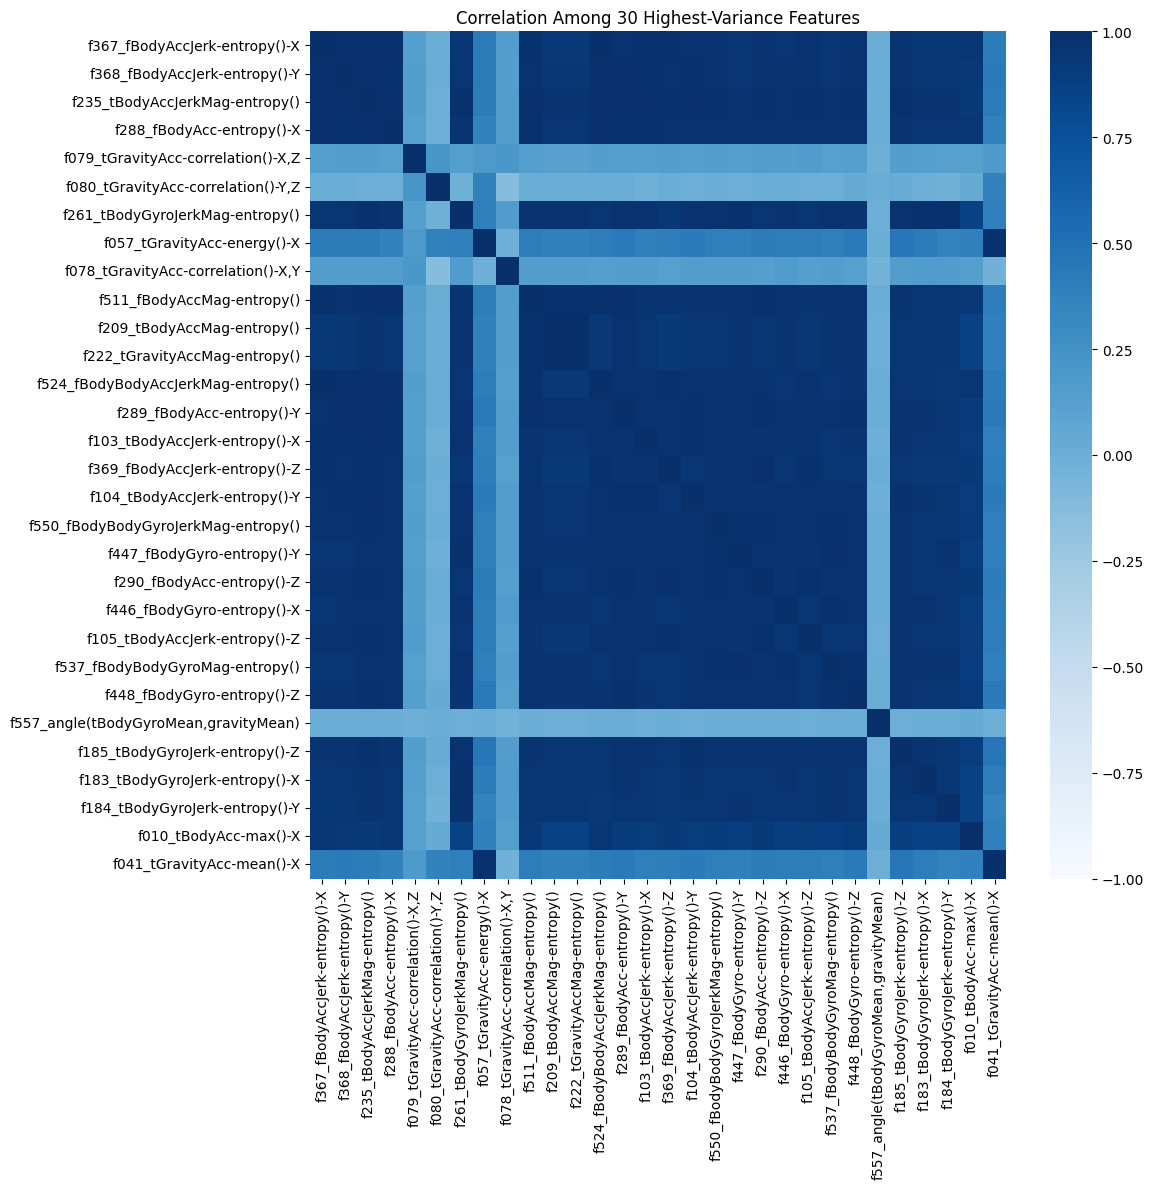

In [ ]:
# Checking to see if UC-HAR variables contain similar information.

# Calculating thr correlation matrix
corr_matrix = X_train.corr().abs()
upp_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k = 1).astype(bool))


# Countiing highly correlated feature pairs
for threshold in [0.90, 0.95, 0.99]:
  pair_count = (upp_triangle > threshold).sum().sum()
  print(f"|r| > {threshold}: {pair_count} feature pairs")

# Identifying features involved in correlations above 0.95
high_corr_pairs = (upp_triangle.stack().reset_index())
high_corr_pairs.columns = ["feature_1", "feature_2", "absolute_correlation"]
high_corr_pairs = high_corr_pairs[high_corr_pairs["absolute_correlation"] > 0.95].sort_values("absolute_correlation", ascending = False)
print(high_corr_pairs.head(20))

selected = X_train.var().nlargest(30).index

plt.figure(figsize = (12,12))
sns.heatmap(X_train[selected].corr(), cmap = "Blues", center = 0, vmin = -1, vmax = 1)
plt.title("Correlation Among 30 Highest-Variance Features")
plt.tight_layout()


# Signed correlation check

correlation_matrix_signed = X_train.corr()
top_pairs = high_corr_pairs.head(20).copy()

top_pairs["signed_correlation"] = [correlation_matrix_signed.loc[feature_1, feature_2]
    for feature_1, feature_2 in zip(top_pairs["feature_1"], top_pairs["feature_2"])]

top_pairs["exactly_equal"] = [
    X_train[feature_1].equals(X_train[feature_2])
    for feature_1, feature_2 in zip(top_pairs["feature_1"], top_pairs["feature_2"])]

top_pairs["maximum_absolute_difference"] = [(X_train[feature_1] - X_train[feature_2]).abs().max()
    for feature_1, feature_2 in zip(top_pairs["feature_1"], top_pairs["feature_2"])]

print(top_pairs[
        [
            "feature_1",
            "feature_2",
            "signed_correlation",
            "exactly_equal",
            "maximum_absolute_difference"
        ]].to_string(index=False))

duplicate_column_mask = (X_train.T.duplicated(keep=False))

duplicate_columns = X_train.columns[duplicate_column_mask]

print("Number of columns involved in exact duplicates:", len(duplicate_columns))

print(list(duplicate_columns))


# Note: The important result is the amount of pairs exceed the selected thresholds. Large pairs implies redundancy.

Further examination of the perfectly correlated feature pairs confirmed that they were exact duplicate columns rather than correlations rounded to unity. Forty of the 561 variables were involved in at least one duplicate group. These duplicates included related magnitude means and signal-magnitude-area variables, as well as repeated body-acceleration and gravity-acceleration magnitude statistics. Because groups could contain more than two identical variables, the number of removable features was calculated as the sum of \($n_g-1$\) across duplicate groups rather than by removing all 40 involved columns. The duplicates were retained in the official 561-feature baseline to preserve comparability with previous UCI-HAR studies, but their presence provides further justification for dimensionality reduction and limits the interpretability of individual feature coefficients and importance values.

# **1.7. Examining PCA-explained Variance**

90% variance :  63 components
95% variance :  102 components
99% variance :  179 components
At 20 components, we have a cumulative variance of 77.37%.
At 50 components, we have a cumulative variance of 87.52%.
At 100 components, we have a cumulative variance of 94.89%.
At 200 components, we have a cumulative variance of 99.36%.


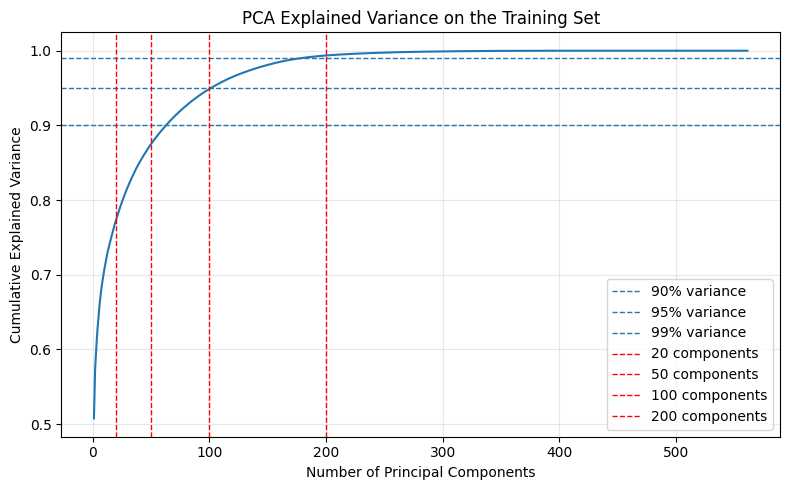

 components  variance_retained_percent  dimensions_removed  dimensionality_reduction_percent
         20                      77.37                 541                             96.43
         50                      87.52                 511                             91.09
        100                      94.89                 461                             82.17
        200                      99.36                 361                             64.35


In [ ]:
# PCA can estimate how many components are needed witohut too much loss in information.

scaler =  stsc()
X_scaled = scaler.fit_transform(X_train)

pca = PCA()
pca.fit(X_scaled)

cum_var = np.cumsum(pca.explained_variance_ratio_)

# Determining how many components are required to preserve selecrted variance levels:
for target in [0.90, 0.95, 0.99]:
  n_components = (np.argmax(cum_var >= target) + 1)
  print(f"{target:.0%} variance : ", f"{n_components} components")

for index in [20, 50, 100, 200]:
  print(f"At {index} components, we have a cumulative variance of {(cum_var[index - 1])*100:0.2f}%.")

# Plotting the cumulative explained variance:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var)

for target in [0.90, 0.95, 0.99]:
    plt.axhline(target, linestyle="--", linewidth=1, label=f"{target:.0%} variance")

for index in [20, 50, 100, 200]:
    plt.axvline(index, linestyle="--", color = 'r', linewidth=1, label=f"{index} components")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance on the Training Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# We are using this analysis to judge whether the proposed budgets of 200, 100, 50, and 20 components are reasonable.
# We are not changing the budgets solely to maximize test performance.

component_budgets = [20, 50, 100, 200]

pca_summary = pd.DataFrame({
    "components": component_budgets,
    "variance_retained_percent": [
        cum_var[k - 1] * 100
        for k in component_budgets
    ]})

pca_summary["dimensions_removed"] = (561 - pca_summary["components"])

pca_summary["dimensionality_reduction_percent"] = (1 - pca_summary["components"] / 561) * 100

print(pca_summary.round(2).to_string(index=False))



PCA demonstrated that the original 561-dimensional representation contained substantial redundancy. After feature standardization, 63 principal components preserved 90% of the total variance, 102 preserved 95%, and 179 preserved 99%. At the proposed experimental budgets, 20, 50, 100, and 200 components retained 77.37%, 87.52%, 94.89%, and 99.36% of cumulative variance, respectively. The 100-component representation therefore preserved approximately 95% of the variance while reducing dimensionality by 82.17%. Nevertheless, explained variance was treated as a descriptive measure rather than a direct indicator of classification performance because PCA does not use activity labels.

# **1.8. Visualizing Activity and Participant Structure**

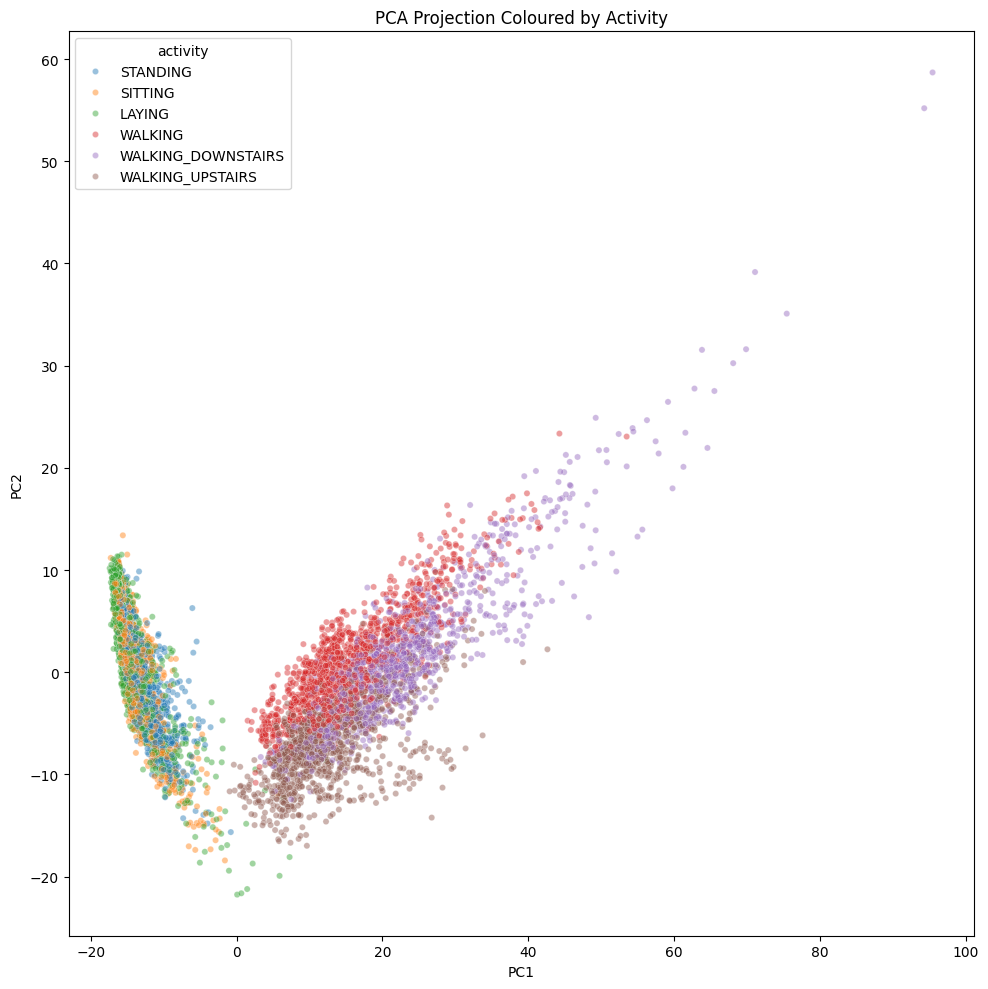

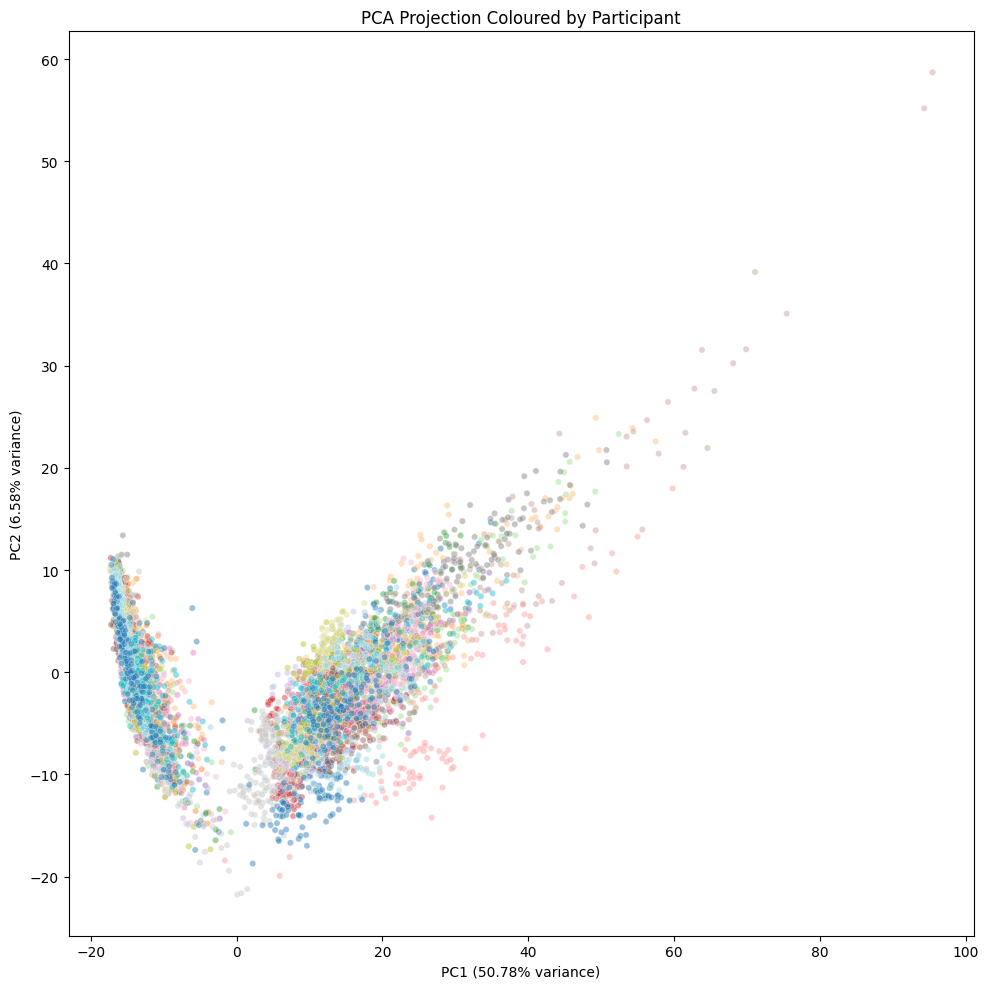

PC1 variance: 50.78 %
PC2 variance: 6.58 %
Total variance shown: 57.36 %
      PC1       PC2  distance_from_origin           activity subject
95.462143 58.697440            112.064313 WALKING_DOWNSTAIRS      19
94.316387 55.194715            109.279629 WALKING_DOWNSTAIRS      19
75.456851 35.092571             83.217936 WALKING_DOWNSTAIRS      19
71.106755 39.162915             81.178227 WALKING_DOWNSTAIRS      19
69.876627 31.610864             76.694131 WALKING_DOWNSTAIRS      19
68.108986 30.245013             74.522445 WALKING_DOWNSTAIRS      19
63.830239 31.547421             71.200696 WALKING_DOWNSTAIRS      19
65.532612 27.521438             71.077091 WALKING_DOWNSTAIRS      19
62.800710 27.758088             68.661784 WALKING_DOWNSTAIRS      19
64.580862 21.950280             68.209255 WALKING_DOWNSTAIRS      19
61.549300 23.435340             65.859938 WALKING_DOWNSTAIRS      19
59.168949 26.456036             64.814245 WALKING_DOWNSTAIRS      19
61.284986 20.098540           

In [ ]:
# Two-component PCA projections can show whether observations form visible groups.

pca_2d = PCA(n_components = 2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

pca_frame = pd.DataFrame({"PC1": X_pca_2d[:, 0], "PC2": X_pca_2d[:, 1], "activity": y_names, "subject": subject_train.astype(str)})

pc1_variance = (pca_2d.explained_variance_ratio_[0]* 100)
pc2_variance = (pca_2d.explained_variance_ratio_[1]* 100)
two_component_variance = (pca_2d.explained_variance_ratio_.sum()* 100)

plt.figure(figsize=(10, 10))
sns.scatterplot(data=pca_frame, x="PC1", y="PC2", hue="activity", alpha=0.45, s=20)
plt.title("PCA Projection Coloured by Activity")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 10))
sns.scatterplot(data=pca_frame, x="PC1", y="PC2", hue="subject", palette = "tab20", alpha=0.45, s=20, legend = False)
plt.title("PCA Projection Coloured by Participant")
plt.xlabel(f"PC1 ({pc1_variance:.2f}% variance)")
plt.ylabel(f"PC2 ({pc2_variance:.2f}% variance)")
plt.tight_layout()
plt.show()

print("PC1 variance:", round(pc1_variance, 2),"%")
print("PC2 variance:", round(pc2_variance, 2),"%")
print("Total variance shown:", round(two_component_variance, 2),"%")

pca_frame["distance_from_origin"] = np.sqrt(pca_frame["PC1"]**2 + pca_frame["PC2"]**2)

extreme_observations = (pca_frame.sort_values("distance_from_origin", ascending=False).head(20))

print(extreme_observations[[
          "PC1",
          "PC2",
          "distance_from_origin",
          "activity",
          "subject"
        ]].to_string(index=False))

print("Activities among the 20 most extreme observations")

print(extreme_observations["activity"].value_counts().to_string())
print("\nParticipants among the 20 most extreme observations")
print(extreme_observations["subject"].value_counts().to_string())

downstairs = pca_frame[pca_frame["activity"]== "WALKING_DOWNSTAIRS"].copy()

downstairs_summary = (downstairs.groupby("subject").agg(observations=("PC1", "size"), mean_PC1=("PC1", "mean"), mean_PC2=("PC2", "mean"), maximum_distance=( "distance_from_origin","max"))
    .sort_values("maximum_distance", ascending=False))

print(downstairs_summary.round(2).to_string())

pca_frame["original_row"] = np.arange(len(pca_frame))

print(pca_frame.sort_values("distance_from_origin", ascending=False)
    .head(20)[[
          "original_row",
          "PC1",
          "PC2",
          "activity",
          "subject"
        ]].to_string(index=False))

# Separation by activity suggests the features contain useful classification information.
# Overlap betweein sitting and standing, or between any two activites may predict common classificaiton errors.
# Strong clustering by participant suggests participant-specific movement patterns, which will need subject-separated evaluation.
# Poor separation in two dimnesions does not prove that the activites are inseparable in th efull feature space.



The two-dimensional PCA projection revealed two broad activity regions. SITTING, STANDING, and LAYING were concentrated primarily at negative PC1 values, whereas WALKING, WALKING_UPSTAIRS, and WALKING_DOWNSTAIRS occupied predominantly positive PC1 values. This suggests that the first principal component captures a major distinction between stationary and dynamic activities. Considerable overlap remained within each broad category, particularly among the stationary activities and among the walking activities. When observations were coloured by participant, colours were generally intermixed rather than forming isolated participant clusters. Activity-related variation therefore appeared more visually prominent than participant identity in the first two components, although participant-specific differences may remain in higher-dimensional directions and were reflected in the grouped cross-validation results.

Examination of the 20 observations located farthest from the origin in the first two principal components showed that 19 represented walking downstairs and 17 belonged to Participant 19. Most of these observations occurred within a concentrated sequence of original dataset rows, suggesting that they correspond to overlapping windows from a single distinctive activity episode rather than independent measurement errors. Participant 19 also displayed the largest mean PC1 score and maximum two-dimensional PCA distance for walking downstairs. Similar, although less pronounced, patterns were observed for Participants 6 and 14. Consequently, these observations were retained as plausible examples of genuine participant-specific movement variation. This finding further supports the use of participant-grouped cross-validation to prevent correlated windows from the same participant from appearing in both training and validation subsets.

# **2. Experimental Design**

## 2. Experimental Design

The preliminary analysis established that the 561-feature UCI-HAR representation contains substantial redundancy, motivating an examination of dimensionality reduction under participant-independent validation. The baseline Logistic Regression model also exhibited variation across validation folds, indicating that classification performance depends on the participants being evaluated.

The experiment investigates whether reducing the number of input dimensions can preserve cross-participant classification performance while lowering computational requirements. It also examines how the relationship between dimensionality, classification performance, and computational cost differs across classifiers and feature-reduction methods.

A factorial experimental design was constructed with three factors:

---
| Factor | Levels |
|---|---|
| Reduction method | PCA and ANOVA-F feature selection |
| Feature budget | 20, 50, 100, and 200 dimensions |
| Classifier | Logistic Regression, RBF Support Vector Machine, and k-Nearest Neighbours |
---

The combination of two reduction methods, four dimensionality budgets, and three classifiers produced 24 reduced-feature treatments. Three additional full-feature controls, using all 561 features, increased the total to 27 configurations.

Each configuration was evaluated using the same five participant-grouped validation folds established in Section 1.4.B. Consequently, the experimental design consisted of 135 configuration–fold combinations. The common validation folds enabled matched treatment comparisons while preventing participant overlap between training and validation within each fold.

Validation macro-F1 was selected as the primary classification performance metric. Secondary measures included accuracy, the training–validation macro-F1 gap, model fitting time, batch prediction time, and single-observation inference latency.

Each classifier was evaluated using three hyperparameter values per treatment. The hyperparameter producing the highest mean validation macro-F1 across the five folds was retained for the treatment summary, resulting in 405 fitted pipelines across the complete experiment.

To prevent preprocessing leakage, standardization and dimensionality reduction were implemented within scikit-learn pipelines and fitted independently on each training fold. ANOVA-F feature selection therefore used only the corresponding training-fold activity labels.

The statistical analysis was primarily descriptive. Factor-level summaries, paired differences between reduction methods, and paired comparisons against full-feature controls were used to evaluate observed classification trade-offs. These analyses were not interpreted as formal tests of statistical significance.

Finally, candidate configurations were screened using a one-standard-error performance threshold and ranked by measured single-observation inference latency. This selection strategy prioritizes inference speed among configurations with validation performance close to the highest observed mean macro-F1.

The official UCI-HAR test partition was excluded from all analyses in Section 2 and reserved for independent final evaluation.


# **2.1. Defining the Treatments**

In [ ]:
import time
import itertools
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, accuracy_score
from sklearn.exceptions import ConvergenceWarning
import platform
import sklearn
import scipy
import threadpoolctl

print("Python:", platform.python_version())
print("Platform:", platform.platform())
print("Processor:", platform.processor())
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("scikit-learn:", sklearn.__version__)

print("\nThreadpool information:")
for info in threadpoolctl.threadpool_info():
    print(info)

warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_STATE = 42
BUDGETS = [20, 50, 100, 200]
METHODS = ["PCA", "ANOVA-F"]
N_FOLDS = len(cv_splits)

CLASSIFIERS = {
    "LogReg": (LogisticRegression(max_iter=5000), "C", [0.1, 1, 10]),
    "RBF_SVM": (SVC(kernel="rbf", gamma = "scale"), "C", [0.1, 1, 10]),
    "kNN": (KNeighborsClassifier(), "n_neighbors", [5, 15, 25]),
}

def build_pipeline(method, k, classifier):
    steps = [("scaler", StandardScaler())]
    if method == "PCA":
        steps.append(("reducer", PCA(n_components=k, random_state=RANDOM_STATE)))
    elif method == "ANOVA-F":
        steps.append(("reducer", SelectKBest(score_func=f_classif, k=k)))
    steps.append(("classifier", clone(classifier)))
    return Pipeline(steps)

design = [{"method": "Full", "budget": 561, "classifier": c} for c in CLASSIFIERS]
design += [{"method": m, "budget": k, "classifier": c} for m, k, c in itertools.product(METHODS, BUDGETS, CLASSIFIERS)]
design_df = pd.DataFrame(design)
design_df.insert(0, "config_id", range(1, len(design_df) + 1))

print("Treatments:", len(design_df))
print("Hyperparameter values per treatment:", 3)
print("Folds (blocks):", N_FOLDS)
print("Total model fits:", len(design_df) * 3 * N_FOLDS)
print(design_df.to_string(index=False))

Python: 3.13.16
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
Processor: x86_64
NumPy: 2.1.3
SciPy: 1.16.3
scikit-learn: 1.6.1

Threadpool information:
{'user_api': 'blas', 'internal_api': 'openblas', 'num_threads': 2, 'prefix': 'libscipy_openblas', 'filepath': '/usr/local/lib/python3.13/dist-packages/numpy.libs/libscipy_openblas64_-ff651d7f.so', 'version': '0.3.27', 'threading_layer': 'pthreads', 'architecture': 'Haswell'}
{'user_api': 'openmp', 'internal_api': 'openmp', 'num_threads': 2, 'prefix': 'libgomp', 'filepath': '/usr/local/lib/python3.13/dist-packages/scikit_learn.libs/libgomp-a34b3233.so.1.0.0', 'version': None}
{'user_api': 'blas', 'internal_api': 'openblas', 'num_threads': 2, 'prefix': 'libscipy_openblas', 'filepath': '/usr/local/lib/python3.13/dist-packages/scipy.libs/libscipy_openblas-b75cc656.so', 'version': '0.3.29.dev', 'threading_layer': 'pthreads', 'architecture': 'Haswell'}
Treatments: 27
Hyperparameter values per treatment: 3
Folds (blocks): 5
Total model fits: 

The experimental design produced 27 configurations comprising 24 dimensionality-reduced treatments and three full-feature controls. The evaluated dimensionality budgets were 20, 50, 100, and 200 features or components.

The PCA budgets corresponded to cumulative explained-variance proportions of approximately 77.4%, 87.5%, 94.9%, and 99.4%, respectively, based on the exploratory PCA analysis in Section 1.7. These proportions describe variance preservation rather than guaranteed classification performance.

PCA and ANOVA-F were evaluated at identical output dimensionalities to control for the number of retained dimensions. However, this does not imply equal computational requirements. PCA constructs new orthogonal components using an unsupervised transformation, whereas ANOVA-F retains original features based on their individual association with the activity classes. Unlike PCA, univariate ANOVA-F selection does not explicitly account for redundancy among retained features.

The classifiers represented three different modeling approaches: Logistic Regression as a regularized linear classifier, RBF SVM as a nonlinear kernel-based classifier, and kNN as a distance-based, instance-based classifier.

Logistic Regression and RBF SVM were evaluated with regularization values C = 0.1, 1, and 10. The RBF kernel parameter was held at gamma = "scale". For kNN, the evaluated neighbourhood sizes were 5, 15, and 25.

The use of three hyperparameter candidates per classifier maintained a consistent search-count budget, although equal candidate counts do not imply equal optimization difficulty or computational effort. The selected hyperparameters and final treatment comparisons are presented in the following sections.

# **2.2. Running the Blocked Factorial Experiment**

In [ ]:
records = []
start = time.time()

for row in design_df.itertuples():
    base_model, param_name, param_values = CLASSIFIERS[row.classifier]
    for value in param_values:
        model = clone(base_model).set_params(**{param_name: value})
        for fold, (train_index, validation_index) in enumerate(cv_splits, start=1):
            pipe = build_pipeline(row.method, row.budget, model)
            X_tr, X_va = X_cv.iloc[train_index], X_cv.iloc[validation_index]
            y_tr, y_va = y_cv.iloc[train_index], y_cv.iloc[validation_index]
            t0 = time.perf_counter()
            pipe.fit(X_tr, y_tr)
            fit_time = time.perf_counter() - t0

            # Batch Prediction Timing
            t0 = time.perf_counter()
            y_pred = pipe.predict(X_va)
            predict_time = time.perf_counter() - t0

            batch_ms_per_sample = (predict_time / len(X_va) * 1000)

            # Reproducible representative sample
            rng = np.random.default_rng(RANDOM_STATE + fold)

            sample_indices = rng.choice(len(X_va), size=min(30, len(X_va)), replace=False)

            # Warm-up
            for idx in sample_indices[:5]:
                pipe.predict(X_va.iloc[[idx]])

            latencies = []

            for idx in sample_indices:
                sample = X_va.iloc[[idx]]

                t0 = time.perf_counter()
                pipe.predict(sample)

                latencies.append((time.perf_counter() - t0) * 1000)

            single_ms = np.median(latencies)

            records.append({
                "config_id": row.config_id,
                "method": row.method,
                "budget": row.budget,
                "classifier": row.classifier,
                "param": f"{param_name}={value}",
                "fold": fold,
                "macro_f1": f1_score(y_va, y_pred, average="macro"),
                "accuracy": accuracy_score(y_va, y_pred),
                "train_macro_f1": f1_score(y_tr, pipe.predict(X_tr), average="macro"),
                "fit_time_s": fit_time,
                "predict_time_s": predict_time,
                "n_validation": len(y_va),
                "batch_ms_per_sample": batch_ms_per_sample,
                "single_ms": single_ms
            })
    print(f"Config {row.config_id:2d}/{len(design_df)} done  ({time.time() - start:.0f} s elapsed)")

raw_results = pd.DataFrame(records)
raw_results.to_csv("phase_c_raw_results.csv", index=False)

Config  1/27 done  (115 s elapsed)
Config  2/27 done  (327 s elapsed)
Config  3/27 done  (372 s elapsed)
Config  4/27 done  (535 s elapsed)
Config  5/27 done  (572 s elapsed)
Config  6/27 done  (588 s elapsed)
Config  7/27 done  (701 s elapsed)
Config  8/27 done  (744 s elapsed)
Config  9/27 done  (760 s elapsed)
Config 10/27 done  (846 s elapsed)
Config 11/27 done  (899 s elapsed)
Config 12/27 done  (922 s elapsed)
Config 13/27 done  (1013 s elapsed)
Config 14/27 done  (1119 s elapsed)
Config 15/27 done  (1145 s elapsed)
Config 16/27 done  (1191 s elapsed)
Config 17/27 done  (1226 s elapsed)
Config 18/27 done  (1237 s elapsed)
Config 19/27 done  (1305 s elapsed)
Config 20/27 done  (1347 s elapsed)
Config 21/27 done  (1361 s elapsed)
Config 22/27 done  (1456 s elapsed)
Config 23/27 done  (1504 s elapsed)
Config 24/27 done  (1520 s elapsed)
Config 25/27 done  (1603 s elapsed)
Config 26/27 done  (1681 s elapsed)
Config 27/27 done  (1701 s elapsed)


All 27 treatment configurations were evaluated using three hyperparameter values across five participant-grouped validation folds, producing 405 fitted pipelines.

For each pipeline, validation macro-F1, validation accuracy, and training macro-F1 were recorded. Fitting time was measured using `time.perf_counter()` and included standardization, dimensionality reduction where applicable, and classifier training.

Computational efficiency was evaluated using batch prediction time and single-observation inference latency. Batch prediction time was measured across each validation fold and normalized by its observation count. Single-observation latency was measured using up to 30 reproducibly sampled validation observations per fold, following five warm-up predictions. Each sampled observation was timed once, and the median latency was retained.

All inference measurements included preprocessing and classifier prediction. The measurements were obtained in the notebook environment and do not directly represent performance on smartphones or wearable devices.

Raw experimental measurements were exported to `phase_c_raw_results.csv` for subsequent analysis.

# **2.3. Summarizing Treatment Performance**

In [ ]:
param_summary = (raw_results.groupby(["config_id", "param"])["macro_f1"].mean().reset_index())
best_param = param_summary.loc[param_summary.groupby("config_id")["macro_f1"].idxmax(), ["config_id", "param"]]

results = raw_results.merge(best_param, on=["config_id", "param"])
results["label"] = results["method"] + "-" + results["budget"].astype(str) + " | " + results["classifier"]

summary = (results.groupby(["config_id", "label", "method", "budget", "classifier", "param"])
    .agg(mean_macro_f1=("macro_f1", "mean"),
         sd_macro_f1=("macro_f1", "std"),
         min_macro_f1=("macro_f1", "min"),
         mean_accuracy=("accuracy", "mean"),
         mean_train_f1=("train_macro_f1", "mean"),
         mean_fit_time_s=("fit_time_s", "mean"),
         mean_predict_time_s=("predict_time_s", "mean"),
         mean_batch_ms=("batch_ms_per_sample", "mean"),
         mean_single_ms=("single_ms", "mean"),
         sd_single_ms=("single_ms", "std"))
    .reset_index())
summary["se_macro_f1"] = summary["sd_macro_f1"] / np.sqrt(N_FOLDS)
summary["gap"] = summary["mean_train_f1"] - summary["mean_macro_f1"]
summary["dim_reduction_pct"] = (1 - summary["budget"] / 561) * 100
summary = summary.sort_values("mean_macro_f1", ascending=False).reset_index(drop=True)

report_columns = ["label", "param", "mean_macro_f1", "sd_macro_f1", "min_macro_f1", "mean_accuracy", "gap", "mean_fit_time_s", "mean_batch_ms", "mean_single_ms", "sd_single_ms", "dim_reduction_pct"]

print(summary[report_columns].round(4).to_string(index=False))

                label          param  mean_macro_f1  sd_macro_f1  min_macro_f1  mean_accuracy    gap  mean_fit_time_s  mean_batch_ms  mean_single_ms  sd_single_ms  dim_reduction_pct
    Full-561 | LogReg           C=10         0.9269       0.0381        0.8697         0.9280 0.0730           9.5419         0.0187          4.9625        1.5645             0.0000
ANOVA-F-200 | RBF_SVM           C=10         0.9264       0.0311        0.8724         0.9260 0.0518           0.4612         0.2952          6.5815        2.2053            64.3494
   Full-561 | RBF_SVM           C=10         0.9237       0.0255        0.8887         0.9252 0.0750           1.6908         0.8039          5.5050        0.2471             0.0000
     PCA-200 | LogReg           C=10         0.9231       0.0369        0.8668         0.9240 0.0739           8.4212         0.0369          4.5441        0.2449            64.3494
    PCA-200 | RBF_SVM            C=1         0.9222       0.0263        0.8982         0.9

The highest mean validation macro-F1 was achieved by full-feature Logistic Regression with C = 10, obtaining 0.9269 (SD = 0.0381). The strongest reduced-feature configuration was ANOVA-F-200 with RBF SVM at C = 10, which achieved 0.9264 (SD = 0.0311). This configuration reduced the representation from 561 to 200 features, corresponding to a dimensionality reduction of 64.35%, while producing a mean macro-F1 only 0.0005 below the highest-scoring full-feature configuration.

Other high-performing treatments included full-feature RBF SVM (0.9237), PCA-200 Logistic Regression (0.9231), PCA-200 RBF SVM (0.9222), and ANOVA-F-200 Logistic Regression (0.9205). These observations indicate that dimensionality reduction to 200 dimensions preserved much of the classification performance achieved with all 561 original features.

Across the 24 reduced treatments, the average validation macro-F1 increased with dimensionality: 0.8513 at 20 dimensions, 0.8732 at 50, 0.8978 at 100, and 0.9108 at 200. This pattern suggests substantial observed performance losses under aggressive reduction, followed by diminishing improvements as the feature budget increased.

When averaged across reduced treatments, RBF SVM achieved a mean macro-F1 of 0.8957, Logistic Regression achieved 0.8947, and kNN achieved 0.8594. PCA produced a slightly higher overall mean than ANOVA-F (0.8886 versus 0.8779), although the relative advantage varied across classifiers and dimensionality budgets.

The training–validation macro-F1 gap also varied across treatments. For instance, full-feature Logistic Regression exhibited a gap of 0.0730, whereas ANOVA-F-200 RBF SVM exhibited a gap of 0.0518. A smaller gap does not necessarily demonstrate superior generalization because it can reflect reduced training performance rather than increased validation performance.

Among the reduced treatments, ANOVA-F-100 produced comparatively low fold-to-fold variability for Logistic Regression (SD = 0.0150) and RBF SVM (SD = 0.0154), with respective worst-fold macro-F1 values of 0.8867 and 0.8881. These results suggest that 100 selected features may offer relatively consistent observed performance across the five validation folds, although consistency across these folds cannot establish stability across the broader population of unseen participants.

The computational measurements did not show a uniformly decreasing relationship between dimensionality and inference latency. For example, ANOVA-F-200 RBF SVM required an average fitting time of 0.4296 seconds per fold, compared with 1.7966 seconds for full-feature RBF SVM. However, its measured single-observation inference latency was 6.0428 milliseconds, compared with 6.1768 milliseconds for the full-feature model, a much smaller difference.

Overall, the results indicate that substantial dimensionality reduction can preserve predictive performance and, for certain classifiers, reduce fitting cost. However, the benefits for single-observation inference latency depend on the complete pipeline and cannot be inferred from dimensionality alone.

# **2.4. Analysis of Variance with Folds as Blocks**

In [ ]:
reduced = results[results["method"] != "Full"].copy()

# Descriptive Factorial Summary
factorial_summary = (reduced.groupby(["classifier", "method", "budget"])
  .agg(mean_macro_f1 = ("macro_f1", "mean"),
       sd_macro_f1 = ("macro_f1", "std"),
       min_macro_f1 = ("macro_f1", "min"),
       mean_fit_time = ("fit_time_s", "mean"),
       mean_single_ms = ("single_ms", "mean"),)
  .reset_index())

print("Factorial Treatment Performamnmce: ")
print(factorial_summary.round(4).to_string(index = False))

# PCA vs. ANOVA-F, paired within the same classifier, budget, and fold
method_pairs = (reduced.pivot_table(
    index = ["classifier", "budget", "fold"],
    columns = "method",
    values = "macro_f1",
).dropna(subset = ["PCA", "ANOVA-F"]).reset_index())

method_pairs["PCA_minus_ANOVA"] = method_pairs["PCA"] - method_pairs["ANOVA-F"]

method_comparison = (method_pairs.groupby(["classifier", "budget"])["PCA_minus_ANOVA"]
  .agg(mean_difference = "mean",
       sd_difference = "std",
       min_difference = "min",
       max_difference = "max").reset_index())

print("\nPCA vs. ANOVA-F macro-F1: ")
print(method_comparison.round(4).to_string(index = False))

for factor in ["classifier", "method", "budget"]:
  print(f"\nDescriptive Performance by {factor}: ")
  print(reduced.groupby(factor)["macro_f1"].agg(["mean", "std", "min", "max"]).round(4).to_string())


fold_matrix = results.pivot(index="fold", columns="label", values="macro_f1")

assert not fold_matrix.isna().any().any()

Factorial Treatment Performamnmce: 
classifier  method  budget  mean_macro_f1  sd_macro_f1  min_macro_f1  mean_fit_time  mean_single_ms
    LogReg ANOVA-F      20         0.8445       0.0321        0.7929         4.3443          5.6506
    LogReg ANOVA-F      50         0.8830       0.0261        0.8520         6.3361          5.7047
    LogReg ANOVA-F     100         0.9067       0.0150        0.8867         7.7216          6.0949
    LogReg ANOVA-F     200         0.9205       0.0367        0.8594         3.5335          4.5287
    LogReg     PCA      20         0.8734       0.0337        0.8305        10.7599          4.3482
    LogReg     PCA      50         0.8931       0.0391        0.8431         4.9052          5.7796
    LogReg     PCA     100         0.9135       0.0383        0.8558         4.1027          5.1876
    LogReg     PCA     200         0.9231       0.0369        0.8668         8.4212          4.5441
   RBF_SVM ANOVA-F      20         0.8541       0.0360        0.

The factorial analysis examined the 24 reduced-feature treatments using five participant-grouped validation folds, producing 120 treatment–fold performance observations. The three full-feature controls were excluded because they do not possess a feature-reduction method or reduced dimensionality budget.

Descriptive aggregation indicated that the dimensionality budget was strongly associated with observed classification performance. Across reduction methods and classifiers, mean macro-F1 increased from 0.8513 at 20 dimensions to 0.9108 at 200 dimensions. The largest differences were observed between the more aggressively reduced treatments and those retaining at least 100 dimensions.

Classifier-level averages were 0.8957 for RBF SVM, 0.8947 for Logistic Regression, and 0.8594 for kNN. Thus, RBF SVM and Logistic Regression achieved similar average performance across the tested reduced configurations, while kNN generally performed less effectively.

Reduction-method averages also showed a difference: PCA achieved an overall mean macro-F1 of 0.8886 compared with 0.8779 for ANOVA-F. However, this advantage was not consistent across all classifier and feature-budget combinations.

Within-fold paired comparisons between PCA and ANOVA-F indicated that PCA generally performed better at smaller dimensionality budgets. For Logistic Regression, PCA exceeded ANOVA-F by 0.0289 macro-F1 at 20 dimensions, but the difference decreased to 0.0026 at 200 dimensions. For RBF SVM, PCA exceeded ANOVA-F by 0.0202 at 20 dimensions, whereas ANOVA-F performed slightly better at 200 dimensions, with a PCA-minus-ANOVA-F difference of −0.0041.

For kNN, the strongest observed advantage for PCA occurred at 50 dimensions (0.0323 macro-F1). At 200 dimensions, ANOVA-F outperformed PCA by 0.0137 macro-F1.

These patterns demonstrate that the effect of the reduction method depended on both the classifier and the retained dimensionality. One plausible explanation is that PCA can represent correlated information more efficiently under restrictive budgets, whereas ANOVA-F may retain informative original features as the budget increases. However, the experiment does not directly establish the mechanism responsible for these differences.

The analysis was descriptive rather than inferential. Means, standard deviations, performance ranges, and within-fold differences were reported without formal significance testing. The same grouped folds were used across treatments, and treatment-specific hyperparameters were selected using those validation results. Consequently, the reported comparisons characterize the observed development-stage performance trade-offs and should not be interpreted as statistically established population-level effects.

# **2.5. Paired Comparisons Against the Full-Feature Control**

In [ ]:
baseline = results[results["method"] == "Full"][["classifier", "fold", "macro_f1"]].rename(columns={"macro_f1": "baseline_f1"})
paired = reduced.merge(baseline, on=["classifier", "fold"])
paired["difference"] = paired["macro_f1"] - paired["baseline_f1"]

comparison_rows = []

for keys, g in paired.groupby(["label", "method", "budget", "classifier"]):
    label, method, budget, classifier = keys
    differences = g["difference"]

    comparison_rows.append({
        "label": label,
        "method": method,
        "budget": budget,
        "classifier": classifier,
        "mean_difference": differences.mean(),
        "sd_difference": differences.std(ddof=1),
        "min_difference": differences.min(),
        "max_difference": differences.max(),
        "folds_better": int((differences > 0).sum()),
        "folds_worse": int((differences < 0).sum()),
        "folds_equal": int((differences == 0).sum())})

comparison_vs_full = pd.DataFrame(comparison_rows)

comparison_vs_full = comparison_vs_full.sort_values(["classifier", "method", "budget"])
print(comparison_vs_full.round(4).to_string(index=False))

                label  method  budget classifier  mean_difference  sd_difference  min_difference  max_difference  folds_better  folds_worse  folds_equal
  ANOVA-F-20 | LogReg ANOVA-F      20     LogReg          -0.0824         0.0193         -0.1109         -0.0614             0            5            0
  ANOVA-F-50 | LogReg ANOVA-F      50     LogReg          -0.0440         0.0425         -0.0941          0.0122             1            4            0
 ANOVA-F-100 | LogReg ANOVA-F     100     LogReg          -0.0202         0.0311         -0.0608          0.0170             1            4            0
 ANOVA-F-200 | LogReg ANOVA-F     200     LogReg          -0.0064         0.0101         -0.0180          0.0044             2            3            0
      PCA-20 | LogReg     PCA      20     LogReg          -0.0535         0.0120         -0.0660         -0.0392             0            5            0
      PCA-50 | LogReg     PCA      50     LogReg          -0.0338         0.0084  

Each dimensionality-reduced treatment was compared with the corresponding full-feature configuration of the same classifier using the same validation folds. Differences were calculated as the reduced-treatment macro-F1 minus the full-feature macro-F1. Positive values therefore indicate improved classification performance after reduction, while negative values indicate a loss.

At the 200-feature budget, the mean paired differences were relatively small for Logistic Regression and RBF SVM. Logistic Regression showed differences of −0.0038 with PCA and −0.0064 with ANOVA-F. RBF SVM showed a difference of −0.0015 with PCA, whereas ANOVA-F produced an improvement of 0.0026 relative to full-feature RBF SVM.

The kNN classifier also showed benefits from supervised feature selection at the 200-feature budget. ANOVA-F-200 improved the mean macro-F1 by 0.0132 relative to full-feature kNN and outperformed the full-feature model on four of the five validation folds. In contrast, PCA-200 produced a negligible mean difference of −0.0004.

At 100 dimensions, the reduced Logistic Regression and RBF SVM configurations generally experienced modest performance losses. PCA-100 Logistic Regression and PCA-100 RBF SVM produced respective mean differences of −0.0134 and −0.0113 relative to their full-feature controls, with lower scores on all five validation folds.

More aggressive reduction to 20 dimensions produced larger performance losses. Across classifiers and methods, the mean paired differences ranged from approximately −0.0423 to −0.0824 macro-F1. Every 20-dimensional treatment scored below its corresponding full-feature control on all five folds.

The paired comparisons therefore suggest that the 200-dimensional budget offers a favorable observed balance between feature reduction and classification performance, while the 20-dimensional budget introduces more substantial performance losses.

These comparisons are descriptive. No paired significance tests or multiple-comparison corrections were performed in the updated analysis. Consequently, small paired differences cannot be interpreted as evidence of statistical equivalence or noninferiority. Additional independent validation or a prespecified practical performance margin would be needed to support such claims.

# **2.6. Visualizing Factor Effects and Cost**

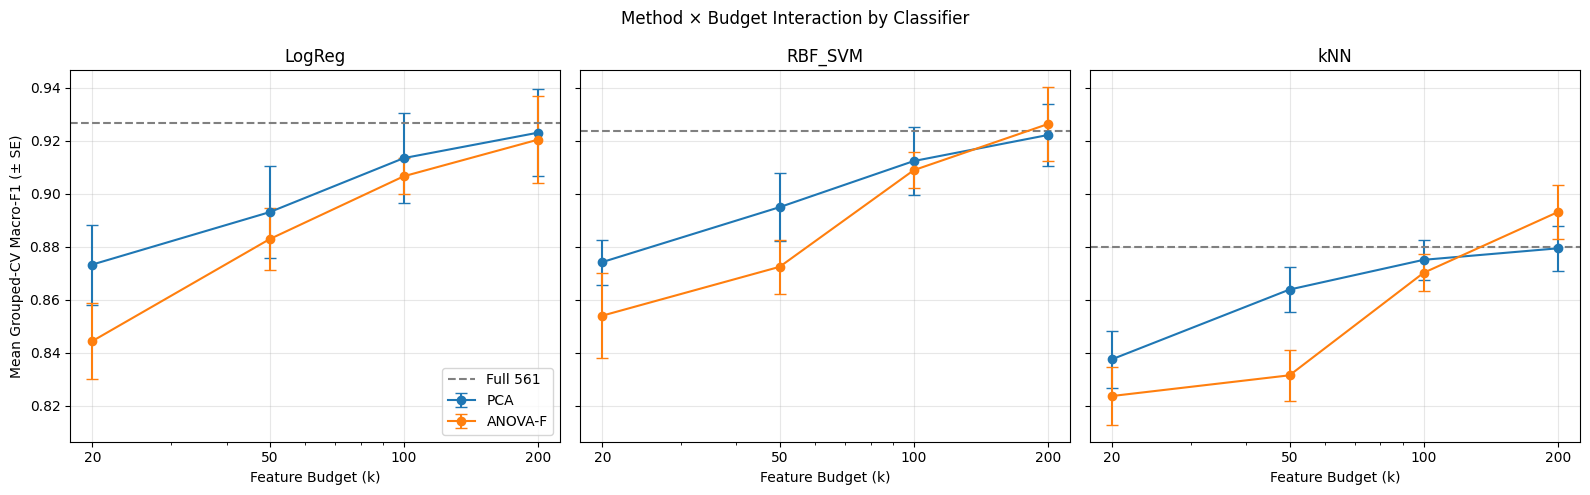

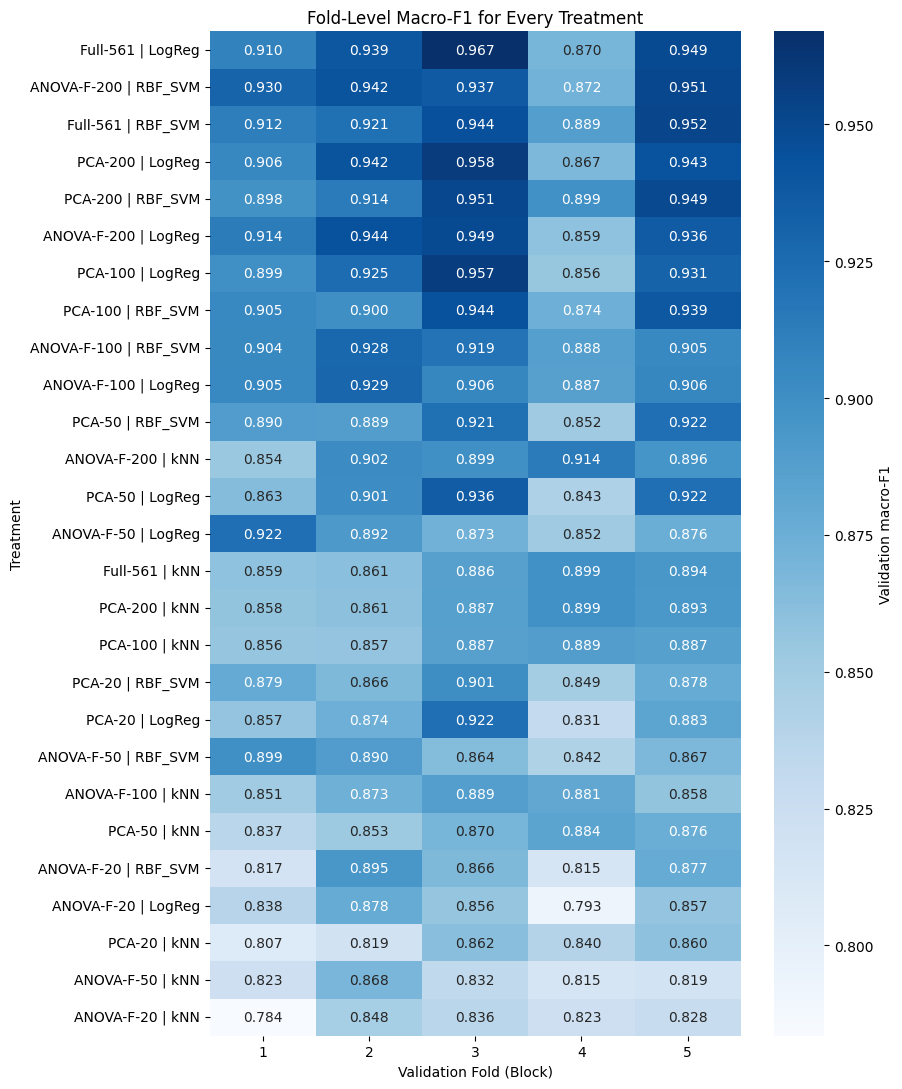

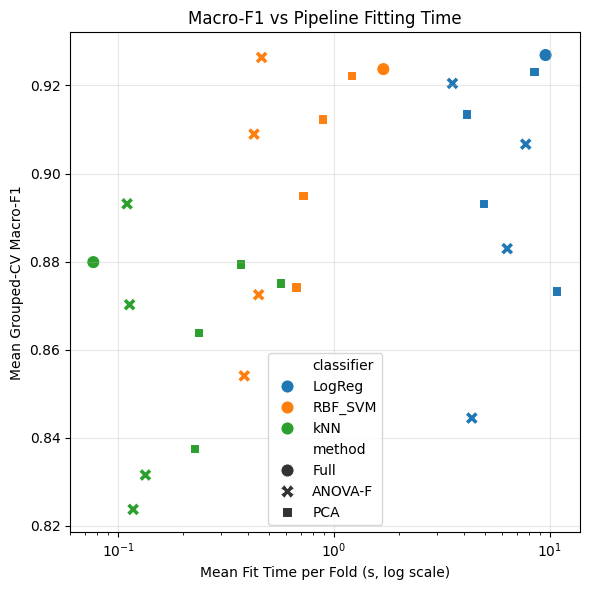

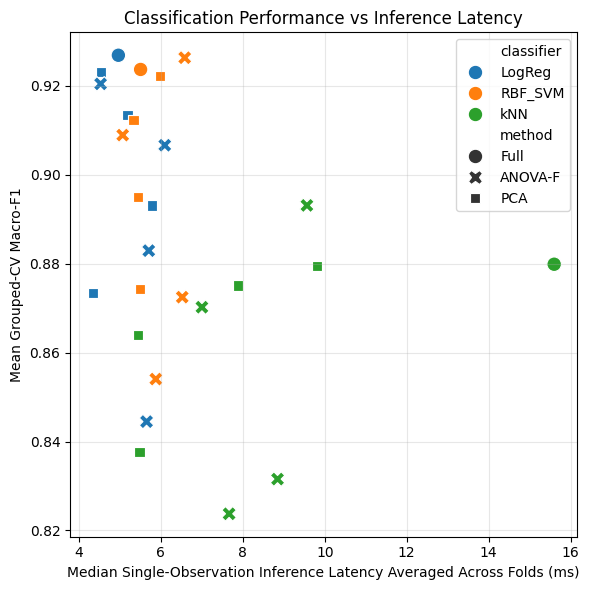

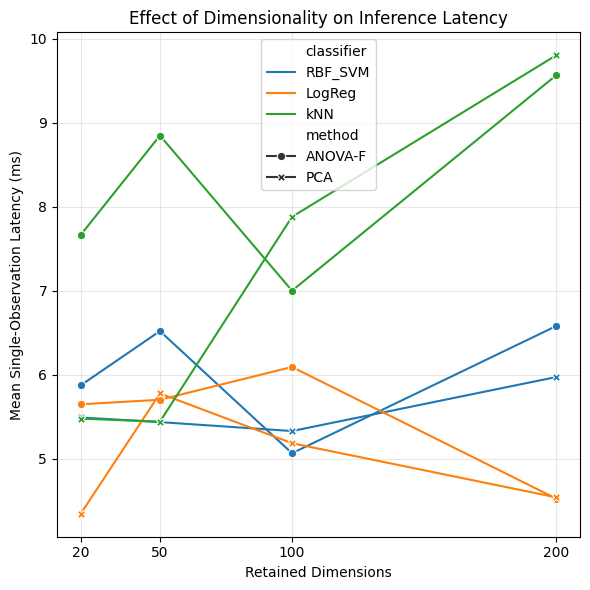

In [ ]:
palette = {"PCA": "tab:blue", "ANOVA-F": "tab:orange"}
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, classifier in zip(axes, CLASSIFIERS):
    sub = summary[summary["classifier"] == classifier]
    for method in METHODS:
        line = sub[sub["method"] == method].sort_values("budget")
        ax.errorbar(line["budget"], line["mean_macro_f1"], yerr=line["se_macro_f1"],
                    marker="o", capsize=4, label=method, color=palette[method])
    full = sub[sub["method"] == "Full"].iloc[0]
    ax.axhline(full["mean_macro_f1"], color="grey", linestyle="--", label="Full 561")
    ax.set_xscale("log")
    ax.set_xticks(BUDGETS)
    ax.set_xticklabels(BUDGETS)
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel("Feature Budget (k)")
    ax.set_title(classifier)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Mean Grouped-CV Macro-F1 (± SE)")
axes[0].legend()
plt.suptitle("Method × Budget Interaction by Classifier")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 11))
heat = fold_matrix[summary["label"]]
sns.heatmap(heat.T, cmap="Blues", annot=True, fmt=".3f", cbar_kws={"label": "Validation macro-F1"})
plt.xlabel("Validation Fold (Block)")
plt.ylabel("Treatment")
plt.title("Fold-Level Macro-F1 for Every Treatment")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 6))
sns.scatterplot(data=summary, x="mean_fit_time_s", y="mean_macro_f1", hue="classifier", style="method", s=90)
plt.xscale("log")
plt.xlabel("Mean Fit Time per Fold (s, log scale)")
plt.ylabel("Mean Grouped-CV Macro-F1")
plt.title("Macro-F1 vs Pipeline Fitting Time")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 6))
sns.scatterplot(
    data=summary,
    x="mean_single_ms",
    y="mean_macro_f1",
    hue="classifier",
    style="method",
    s=110)
plt.xlabel("Median Single-Observation Inference Latency Averaged Across Folds (ms)")
plt.ylabel("Mean Grouped-CV Macro-F1")
plt.title("Classification Performance vs Inference Latency")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 6))
sns.lineplot(
    data=summary[summary["method"] != "Full"],
    x="budget",
    y="mean_single_ms",
    hue="classifier",
    style="method",
    markers=True,
    dashes=False,
    errorbar=None)

plt.xlabel("Retained Dimensions")
plt.ylabel("Mean Single-Observation Latency (ms)")
plt.title("Effect of Dimensionality on Inference Latency")
plt.xticks(BUDGETS)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


The interaction plots demonstrated that classification performance generally improved as the dimensionality budget increased from 20 to 200 features or components. The improvements became smaller at higher budgets, suggesting diminishing predictive returns from retaining additional dimensions within the tested range.

PCA generally outperformed ANOVA-F at smaller feature budgets, although this relationship depended on the classifier. At 200 dimensions, the reduction methods achieved comparatively similar results for Logistic Regression, while ANOVA-F slightly outperformed PCA for RBF SVM and kNN.

The fold-level heatmap showed substantial variation in performance across participant groups. The same configuration could achieve noticeably different macro-F1 values depending on which participants were held out. This reinforces the importance of participant-grouped validation when assessing generalization to individuals absent from the training fold.

The computational plots revealed differences between fitting cost and prediction latency. For example, ANOVA-F-200 RBF SVM required approximately 0.4296 seconds per fold to fit, compared with 1.7966 seconds for full-feature RBF SVM, representing an approximate 4.2-fold reduction in measured fitting time. However, the corresponding single-observation inference latencies were 6.0428 and 6.1768 milliseconds, respectively, showing only a small difference in this benchmark.

The inference-latency plots did not demonstrate a uniform improvement as dimensionality decreased. In several configurations, the overhead associated with preprocessing and prediction was substantial enough that reduced-dimensionality pipelines did not consistently exhibit lower single-observation inference times.

These measurements also differed from batch-average prediction times. The two metrics measure different execution patterns, and their results should not be treated as directly interchangeable.

Overall, the figures demonstrate that dimensionality reduction can improve classification efficiency in some respects, especially model fitting time, without necessarily improving every measure of computational performance. Selection of a resource-efficient HAR configuration therefore requires consideration of both predictive performance and the resource metric relevant to the intended application.

# **2.7. Selecting the Final Configuration**

In [ ]:
best = summary.iloc[0]

threshold = (best["mean_macro_f1"] - best["se_macro_f1"])

# Keep configurations within one standard error of the top mean F1
candidates = summary[summary["mean_macro_f1"] >= threshold].copy()

# Prioritize inference latency, then dimensionality and fitting time
candidates = candidates.sort_values(["mean_single_ms", "budget","mean_fit_time_s"])

selected = candidates.iloc[0]

selection_columns = ["label", "param", "mean_macro_f1", "sd_macro_f1", "budget", "dim_reduction_pct", "mean_fit_time_s", "mean_batch_ms", "mean_single_ms"]

# Best eligible reduced-dimensionality candidate
reduced_candidates = candidates[candidates["method"] != "Full"].copy()

best_reduced = reduced_candidates.sort_values(
    ["mean_macro_f1", "mean_single_ms"],
    ascending=[False, True]).iloc[0]

print("\nSelected inference-first configuration:")
print(selected[selection_columns].to_string())

print("\nBest performing eligible reduced configuration:")
print(best_reduced[selection_columns].to_string())

print("\nBest mean macro-F1:")
print(best[selection_columns].to_string())

print("\nOne-SE threshold:", round(threshold, 4))

print("\nEligible configurations ranked by latency:")
print(candidates[selection_columns].round(4).to_string(index=False))

print("\nSelected configuration:")
print(selected[selection_columns].to_string())

print("\nSelection objective: minimize measured single-observation inference latency subject to the one-SE performance threshold.")

summary.to_csv("phase_c_summary.csv", index=False)
comparison_vs_full.to_csv("phase_c_vs_full.csv", index=False)


Selected inference-first configuration:
label                ANOVA-F-200 | LogReg
param                                 C=1
mean_macro_f1                    0.920471
sd_macro_f1                      0.036721
budget                                200
dim_reduction_pct               64.349376
mean_fit_time_s                  3.533508
mean_batch_ms                    0.017431
mean_single_ms                   4.528739

Best performing eligible reduced configuration:
label                ANOVA-F-200 | RBF_SVM
param                                 C=10
mean_macro_f1                     0.926351
sd_macro_f1                       0.031102
budget                                 200
dim_reduction_pct                64.349376
mean_fit_time_s                   0.461242
mean_batch_ms                     0.295186
mean_single_ms                     6.58153

Best mean macro-F1:
label                Full-561 | LogReg
param                             C=10
mean_macro_f1                 0.926905
sd_macr

The final configuration was selected using a one-standard-error-inspired performance threshold followed by inference-latency-based ranking. This approach was intended to identify a computationally efficient configuration while maintaining classification performance close to the highest-performing treatment.

First, the configuration achieving the highest mean cross-validation macro-F1 was identified. An eligibility threshold was then calculated by subtracting that configuration's estimated standard error from its mean macro-F1. All configurations meeting or exceeding this threshold were considered eligible for final selection.

Among eligible configurations, the model with the lowest mean single-observation inference latency was selected. Feature dimensionality and fitting time were used as secondary ranking criteria when necessary. This selection procedure prioritized measured inference efficiency rather than simply minimizing feature count or maximizing classification accuracy.

The selection criterion was designed to examine whether reductions in computational requirements could be achieved while maintaining competitive classification performance. However, the one-standard-error threshold does not establish statistical equivalence, and the measured latency reflects execution within the notebook environment rather than performance on resource-constrained hardware.

The highest-performing configuration, eligibility threshold, number of eligible treatments, and final selected configuration are reported in the Results section. Following selection, the chosen pipeline was refitted using the complete official training partition and evaluated on the held-out test set.

# **2.8. Auditing the Experimental Result Tables**

In [ ]:
audit = []

def audit_check(name, condition, detail=""):
    audit.append({"check": name, "result": "PASS" if bool(condition) else "FAIL", "detail": detail})

n_design = len(design_df)
n_full = int((design_df["method"] == "Full").sum())
n_reduced = int((design_df["method"] != "Full").sum())
audit_check("27 configurations in design", n_design == 27, f"{n_design}")
audit_check("3 full-feature controls + 24 reduced treatments", n_full == 3 and n_reduced == 24, f"{n_full} + {n_reduced}")

params_per_config = raw_results.groupby("config_id")["param"].nunique()
audit_check("3 hyperparameter values per configuration",
            len(params_per_config) == 27 and params_per_config.eq(3).all(),
            f"configs={len(params_per_config)}, min={params_per_config.min()}, max={params_per_config.max()}")

folds_per_combo = raw_results.groupby(["config_id", "param"])["fold"].nunique()
audit_check("5 folds per configuration-hyperparameter combination",
            len(folds_per_combo) == 81 and folds_per_combo.eq(5).all(),
            f"combinations={len(folds_per_combo)}")
audit_check("Fold IDs are exactly 1-5", set(raw_results["fold"]) == set(range(1, N_FOLDS + 1)), str(sorted(int(f) for f in raw_results["fold"].unique())))

audit_check("405 fitted pipelines in raw results", len(raw_results) == 405, f"{len(raw_results)}")
audit_check("135 selected-parameter fold rows", len(results) == 135, f"{len(results)}")
audit_check("5 selected-parameter folds per configuration",
            results["config_id"].nunique() == 27 and results.groupby("config_id")["fold"].nunique().eq(5).all())
audit_check("27 configuration summaries", len(summary) == 27, f"{len(summary)}")
audit_check("24 paired comparisons against full-feature controls", len(comparison_vs_full) == 24, f"{len(comparison_vs_full)}")

duplicate_counts = {
    "raw_results (config_id, param, fold)": raw_results.duplicated(["config_id", "param", "fold"]).sum(),
    "results (config_id, fold)": results.duplicated(["config_id", "fold"]).sum(),
    "summary (config_id)": summary["config_id"].duplicated().sum(),
    "summary (label)": summary["label"].duplicated().sum(),
    "comparison_vs_full (label)": comparison_vs_full["label"].duplicated().sum(),
}
for key, count in duplicate_counts.items():
    audit_check(f"No duplicate keys: {key}", count == 0, f"{count} duplicates")

tables = {"raw_results": raw_results, "results": results, "summary": summary, "comparison_vs_full": comparison_vs_full}
for name, table in tables.items():
    nan_count = int(table.isna().sum().sum())
    audit_check(f"No NaNs: {name}", nan_count == 0, f"{nan_count} NaNs")

metric_columns = ["macro_f1", "accuracy", "train_macro_f1"]
timing_columns = ["fit_time_s", "predict_time_s", "batch_ms_per_sample", "single_ms"]
audit_check("All metrics within [0, 1]", raw_results[metric_columns].apply(lambda s: s.between(0, 1)).all().all())
audit_check("All timings positive", (raw_results[timing_columns] > 0).all().all())

recomputed_param_means = raw_results.groupby(["config_id", "param"])["macro_f1"].mean().reset_index()
recomputed_best = recomputed_param_means.loc[recomputed_param_means.groupby("config_id")["macro_f1"].idxmax(), ["config_id", "param"]]
param_check = summary[["config_id", "param"]].merge(recomputed_best, on="config_id", suffixes=("_summary", "_recomputed"))
audit_check("Selected hyperparameter is the best mean macro-F1 for every configuration",
            len(param_check) == 27 and (param_check["param_summary"] == param_check["param_recomputed"]).all())

recalc_rows = []
for row in summary.itertuples():
    fold_rows = raw_results[(raw_results["config_id"] == row.config_id) & (raw_results["param"] == row.param)].sort_values("fold")
    f1_values = fold_rows["macro_f1"].to_numpy()
    mean_f1 = f1_values.mean()
    sd_f1 = f1_values.std(ddof=1)
    se_f1 = sd_f1 / np.sqrt(len(f1_values))
    mean_accuracy = fold_rows["accuracy"].mean()
    gap = fold_rows["train_macro_f1"].mean() - mean_f1
    mean_single = fold_rows["single_ms"].mean()
    recalc_rows.append({
        "config_id": row.config_id,
        "label": row.label,
        "param": row.param,
        "n_folds": len(f1_values),
        "summary_mean_f1": row.mean_macro_f1,
        "recalc_mean_f1": mean_f1,
        "summary_sd_f1": row.sd_macro_f1,
        "recalc_sd_f1": sd_f1,
        "summary_se_f1": row.se_macro_f1,
        "recalc_se_f1": se_f1,
        "summary_accuracy": row.mean_accuracy,
        "recalc_accuracy": mean_accuracy,
        "summary_gap": row.gap,
        "recalc_gap": gap,
        "summary_single_ms": row.mean_single_ms,
        "recalc_single_ms": mean_single,
        "match": all(np.isclose(a, b, rtol=0, atol=1e-12) for a, b in [
            (row.mean_macro_f1, mean_f1), (row.sd_macro_f1, sd_f1), (row.se_macro_f1, se_f1),
            (row.mean_accuracy, mean_accuracy), (row.gap, gap), (row.mean_single_ms, mean_single)]),
    })
recalc_df = pd.DataFrame(recalc_rows)

full_logreg_id = summary.loc[(summary["method"] == "Full") & (summary["classifier"] == "LogReg"), "config_id"].iloc[0]
best_reduced_id = summary.loc[summary["method"] != "Full", "config_id"].iloc[0]
spot_ids = list(dict.fromkeys([summary.iloc[0]["config_id"], selected["config_id"], full_logreg_id, best_reduced_id,
                               summary.iloc[len(summary) // 2]["config_id"], summary.iloc[-1]["config_id"]]))
spot_check = recalc_df[recalc_df["config_id"].isin(spot_ids)]

audit_check(f"Spot-check recalculation ({len(spot_check)} configurations)", len(spot_check) >= 3 and spot_check["match"].all(),
            ", ".join(spot_check["label"]))
audit_check("Full recalculation of all 27 summaries", recalc_df["match"].all(), f"{int(recalc_df['match'].sum())}/27 match")

full_means = summary[summary["method"] == "Full"].set_index("classifier")["mean_macro_f1"]
diff_check = comparison_vs_full.merge(summary[["label", "mean_macro_f1"]], on="label")
diff_check["expected_difference"] = diff_check["mean_macro_f1"] - diff_check["classifier"].map(full_means)
audit_check("Paired mean differences equal summary mean differences",
            len(diff_check) == 24 and np.allclose(diff_check["mean_difference"], diff_check["expected_difference"], rtol=0, atol=1e-12))

audit_df = pd.DataFrame(audit)
all_pass = audit_df["result"].eq("PASS").all()

print("Spot-check recalculation (summary vs. fold-level data):")
print(spot_check[["label", "param", "n_folds", "summary_mean_f1", "recalc_mean_f1", "summary_se_f1", "recalc_se_f1", "match"]]
      .round(6).to_string(index=False))

print("\nExperimental Results Audit Report:")
print(audit_df.to_string(index=False))
print(f"\nPassed {int(audit_df['result'].eq('PASS').sum())}/{len(audit_df)} checks")

audit_df.to_csv("phase_c_audit_report.csv", index=False)
recalc_df.to_csv("phase_c_recalculation_check.csv", index=False)

if all_pass:
    raw_results.to_csv("phase_c_raw_results_validated.csv", index=False)
    results.to_csv("phase_c_selected_fold_results_validated.csv", index=False)
    summary.to_csv("phase_c_summary_validated.csv", index=False)
    comparison_vs_full.to_csv("phase_c_vs_full_validated.csv", index=False)
    print("Overall audit: PASS. Validated CSVs exported.")
else:
    print("Overall audit: FAIL. Validated CSVs were NOT exported. Review the failed checks above.")

# **3. Final Evaluation on the Official Test Set**

# **3.1. Loading the Official Test Set**

In [ ]:
X_test = pd.read_csv(DATA_DIR / "test/X_test.txt", sep=r"\s+", header=None, names=feature_names)
y_test = pd.read_csv(DATA_DIR / "test/y_test.txt", sep=r"\s+", header=None, names=["activity_id"])["activity_id"]

subject_test = pd.read_csv(DATA_DIR / "test/subject_test.txt", sep=r"\s+", header=None, names=["subject_id"])["subject_id"]

# Verify the official partition
assert X_test.shape == (2947, 561)
assert len(y_test) == 2947
assert subject_test.nunique() == 9

# Confirm participant separation
assert set(subject_train).isdisjoint(set(subject_test))

# Confirm feature compatibility
assert list(X_train.columns) == list(X_test.columns)

print("Official test set:", X_test.shape)
print("Training subjects:", subject_train.nunique())
print("Test subjects:", subject_test.nunique())
print("Participant separation: PASS")

Official test set: (2947, 561)
Training subjects: 21
Test subjects: 9
Participant separation: PASS


# **3.2. Reconstructing and Fitting the Selected Pipeline**

In [ ]:
# Section 3.2 — Final Model Training

selected_classifier = selected["classifier"]
selected_method = selected["method"]
selected_budget = int(selected["budget"])

# Retrieve the selected hyperparameter
param_name, param_value = selected["param"].split("=")
base_model, _, _ = CLASSIFIERS[selected_classifier]

if param_name == "n_neighbors":
    param_value = int(param_value)
else:
    param_value = float(param_value)

final_classifier = clone(base_model).set_params(**{param_name: param_value})

final_pipeline = build_pipeline(method=selected_method, k=selected_budget, classifier=final_classifier)

# Fit on the complete official training partition
final_pipeline.fit(X_train, y_train)

print("Final classifier:", selected_classifier)
print("Reduction method:", selected_method)
print("Feature budget:", selected_budget)
print("Selected parameter:", selected["param"])

Final classifier: LogReg
Reduction method: ANOVA-F
Feature budget: 200
Selected parameter: C=1


# **3.2.B. Verifying and Freezing the Final Model**

In [ ]:
import json
import hashlib
import joblib
from sklearn.feature_selection import f_classif

EXPECTED_SELECTION = {"method": "ANOVA-F", "budget": 200, "classifier": "LogReg", "param": "C=1"}

def pipeline_fingerprint(pipe):
    parts = [pipe.named_steps["scaler"].mean_, pipe.named_steps["scaler"].scale_]
    reducer = pipe.named_steps.get("reducer")
    if reducer is not None:
        parts.append(reducer.get_support(indices=True) if hasattr(reducer, "get_support") else reducer.components_)
    classifier = pipe.named_steps["classifier"]
    for attribute in ["coef_", "intercept_", "support_vectors_", "dual_coef_", "_fit_X"]:
        if hasattr(classifier, attribute):
            parts.append(getattr(classifier, attribute))
    digest = hashlib.sha256()
    for part in parts:
        digest.update(np.ascontiguousarray(part, dtype=np.float64).tobytes())
    return digest.hexdigest()

validation = []

def validate(name, condition, detail=""):
    if condition is None:
        result = "NOT CHECKED"
    else:
        result = "PASS" if bool(condition) else "FAIL"
    validation.append({"check": name, "result": result, "detail": detail})

scaler_step = final_pipeline.named_steps["scaler"]
reducer_step = final_pipeline.named_steps.get("reducer")
classifier_step = final_pipeline.named_steps["classifier"]

selected_param_name, selected_param_text = selected["param"].split("=")
selected_param_value = float(selected_param_text)

validate("Selected configuration is ANOVA-F-200 | LogReg | C=1",
         selected["method"] == EXPECTED_SELECTION["method"]
         and int(selected["budget"]) == EXPECTED_SELECTION["budget"]
         and selected["classifier"] == EXPECTED_SELECTION["classifier"]
         and selected["param"] == EXPECTED_SELECTION["param"],
         f"{selected['label']} | {selected['param']}")

validate("Final pipeline reduction step matches selected method and budget",
         isinstance(reducer_step, SelectKBest) and reducer_step.k == int(selected["budget"]) and reducer_step.score_func is f_classif,
         f"{type(reducer_step).__name__}, k={getattr(reducer_step, 'k', None)}")

expected_classifier = clone(CLASSIFIERS[selected["classifier"]][0]).set_params(**{selected_param_name: selected_param_value})
validate("Final classifier type and hyperparameters match the cross-validated selection",
         type(classifier_step) is type(expected_classifier)
         and classifier_step.get_params() == expected_classifier.get_params(),
         f"{type(classifier_step).__name__}, {selected_param_name}={classifier_step.get_params()[selected_param_name]}")

validate("Scaler fitted on official training set only (n = 7,352)",
         scaler_step.n_samples_seen_ == len(X_train) == 7352
         and np.allclose(scaler_step.mean_, X_train.mean().to_numpy())
         and np.allclose(scaler_step.scale_, X_train.std(ddof=0).to_numpy()),
         f"n_samples_seen_={scaler_step.n_samples_seen_}")

if isinstance(reducer_step, SelectKBest):
    train_f_scores, _ = f_classif(scaler_step.transform(X_train), y_train)
    expected_support = np.sort(np.argsort(np.nan_to_num(train_f_scores, nan=np.finfo(float).min), kind="mergesort")[-int(selected["budget"]):])
    validate("ANOVA-F scores and selected features reproduced from training data only",
             np.allclose(reducer_step.scores_, train_f_scores, equal_nan=True)
             and np.array_equal(reducer_step.get_support(indices=True), expected_support),
             f"{reducer_step.get_support().sum()} features selected")
else:
    validate("ANOVA-F scores and selected features reproduced from training data only", False,
             "Final pipeline has no ANOVA-F selector")

validate("Classifier classes come from training labels only",
         np.array_equal(classifier_step.classes_, np.sort(y_train.unique())),
         f"classes={list(classifier_step.classes_)}")

reference_pipeline = build_pipeline(method=selected["method"], k=int(selected["budget"]), classifier=expected_classifier)
reference_pipeline.fit(X_train, y_train)
validate("Independent refit on training data reproduces the final model exactly",
         pipeline_fingerprint(reference_pipeline) == pipeline_fingerprint(final_pipeline))

feature_inputs = list(final_pipeline.feature_names_in_)
max_subject_corr = X_train.corrwith(subject_train).abs().max()
validate("Participant IDs are not among predictive features",
         final_pipeline.n_features_in_ == 561
         and feature_inputs == feature_names
         and not any("subject" in name.lower() for name in feature_inputs)
         and max_subject_corr < 0.99,
         f"{final_pipeline.n_features_in_} inputs, max |r| with subject ID = {max_subject_corr:.3f}")

validate("Training and test participants are disjoint",
         set(subject_train).isdisjoint(set(subject_test)),
         f"train={subject_train.nunique()}, test={subject_test.nunique()}")

try:
    cell_history = get_ipython().user_ns.get("In", [])
except NameError:
    cell_history = []
test_tokens = ["X_" + "test", "y_" + "test"]
fit_tokens = ["." + "fit(", "." + "fit_transform(", "." + "partial_fit("]
leaking_lines = [line.strip() for cell in cell_history for line in cell.splitlines()
                 if any(t in line for t in test_tokens) and any(f in line for f in fit_tokens)]
validate("Test data never passed to fit(), fit_transform(), or partial_fit()",
         (len(leaking_lines) == 0) if cell_history else None,
         f"{len(cell_history)} executed cells scanned" if cell_history else "IPython history unavailable")

validation_df = pd.DataFrame(validation)
c1_pass = validation_df["result"].ne("FAIL").all()

FINAL_FINGERPRINT = pipeline_fingerprint(final_pipeline)
selected_feature_names = list(reducer_step.get_feature_names_out()) if hasattr(reducer_step, "get_feature_names_out") else feature_inputs

frozen_record = {
    "selected_model": "ANOVA-F-200 | Logistic Regression | C = 1",
    "label": selected["label"],
    "method": selected["method"],
    "budget": int(selected["budget"]),
    "classifier": selected["classifier"],
    "param": selected["param"],
    "cv_mean_macro_f1": float(selected["mean_macro_f1"]),
    "cv_se_macro_f1": float(selected["se_macro_f1"]),
    "cv_mean_single_ms": float(selected["mean_single_ms"]),
    "training_rows": int(len(X_train)),
    "training_subjects": int(subject_train.nunique()),
    "selected_features": selected_feature_names,
    "fingerprint_sha256": FINAL_FINGERPRINT,
    "sklearn_version": sklearn.__version__,
    "c1_validation": "PASS" if c1_pass else "FAIL",
}

print("C.1 Final Model Validation Summary:")
print(validation_df.to_string(index=False))
print("\nOverall C.1 validation:", "PASS" if c1_pass else "FAIL")

if c1_pass:
    joblib.dump(final_pipeline, "final_model_ANOVA-F-200_LogReg_C1.joblib")
    with open("final_model_record.json", "w") as f:
        json.dump(frozen_record, f, indent=2)
    validation_df.to_csv("final_model_validation.csv", index=False)
    print("\nFrozen model: ANOVA-F-200 | Logistic Regression | C = 1")
    print("Fingerprint:", FINAL_FINGERPRINT)
else:
    raise RuntimeError("C.1 validation FAILED. Model NOT frozen. Test evaluation blocked until all checks pass.")

# **3.3. Final Test Set Classification Report**

In [ ]:
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay)

y_test_pred = final_pipeline.predict(X_test)

test_macro_f1 = f1_score(y_test, y_test_pred, average="macro")

test_accuracy = accuracy_score(y_test, y_test_pred)

print("Final Test Macro-F1:", round(test_macro_f1, 4))
print("Final Test Accuracy:", round(test_accuracy, 4))

labels = sorted(activity_map)

print("\nClassification Report:")
print(classification_report(
        y_test,
        y_test_pred,
        labels=labels,
        target_names=[activity_map[i] for i in labels],
        digits=4))

cm = confusion_matrix(y_test, y_test_pred, labels=labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[activity_map[i] for i in labels])

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Final Held-Out Test Confusion Matrix")
plt.tight_layout()
plt.show()

# **3.4. Post-Evaluation Integrity Check**

In [ ]:
post_checks = pd.DataFrame([
    {"check": "Model unchanged after test evaluation (fingerprint match)",
     "result": "PASS" if pipeline_fingerprint(final_pipeline) == FINAL_FINGERPRINT else "FAIL", "detail": ""},
    {"check": "Scaler still reflects training set only",
     "result": "PASS" if final_pipeline.named_steps["scaler"].n_samples_seen_ == len(X_train) else "FAIL", "detail": ""},
    {"check": "One prediction per official test observation",
     "result": "PASS" if len(y_test_pred) == len(y_test) == 2947 else "FAIL", "detail": ""},
])

final_validation_df = pd.concat([validation_df, post_checks], ignore_index=True)
final_pass = final_validation_df["result"].ne("FAIL").all()

frozen_record.update({
    "test_macro_f1": float(test_macro_f1),
    "test_accuracy": float(test_accuracy),
    "final_validation": "PASS" if final_pass else "FAIL",
})

with open("final_model_record.json", "w") as f:
    json.dump(frozen_record, f, indent=2)
final_validation_df.to_csv("final_model_validation.csv", index=False)

print("C.1 Final Validation Summary (pre- and post-evaluation):")
print(final_validation_df.to_string(index=False))
print("\nSelected model: ANOVA-F-200 | Logistic Regression | C = 1")
print("Test macro-F1:", round(test_macro_f1, 4), "| Test accuracy:", round(test_accuracy, 4))
print("Overall:", "PASS" if final_pass else "FAIL")

# **3.5. Verifying the Inference Timing Benchmark**

In [ ]:
# C.3 — Inference timing benchmark verification (read-only: the original selection is not changed)
import time
from scipy import stats

clock = time.get_clock_info("perf_counter")
bench = []

def bench_check(name, condition, detail=""):
    bench.append({"check": name, "result": "PASS" if bool(condition) else "FAIL", "detail": detail})

bench_src = next((s for s in reversed(In) if "sample_indices" in s and "latencies" in s), "")
if bench_src:
    bench_check("Up to 30 validation observations sampled per fold", "size=min(30, len(X_va))" in bench_src)
    bench_check("Sampling is reproducible per fold (same rows for every configuration)", "default_rng(RANDOM_STATE + fold)" in bench_src)
    bench_check("Five warm-up predictions before timing", "sample_indices[:5]" in bench_src)
    bench_check("One timed predict call per sampled observation", bench_src.count("pipe.predict(sample)") == 1)
    bench_check("Fold statistic is the median of the timed calls", "np.median(latencies)" in bench_src)
    bench_check("Row slicing happens outside the timed region",
                bench_src.find("sample = X_va.iloc[[idx]]") < bench_src.find("t0 = time.perf_counter()\n                pipe.predict(sample)"))
else:
    bench_check("Benchmark source found in notebook history", False, "Run Section 2.2 in this session or verify manually")

fold_n = raw_results.groupby("fold")["n_validation"].first()
n_timed = fold_n.clip(upper=30)
bench_check("Every validation fold has >= 30 observations (30 timed per fold)", (fold_n >= 30).all(),
            ", ".join(f"fold {f}: n={n}" for f, n in fold_n.items()))
bench_check("One latency median per configuration x hyperparameter x fold",
            raw_results.groupby(["config_id", "param", "fold"])["single_ms"].count().eq(1).all() and len(raw_results) == 405)
bench_check("Timed calls per selected configuration = 5 folds x 30 = 150", int(n_timed.sum()) == 150, f"{int(n_timed.sum())}")

recalc_mean = results.groupby("config_id")["single_ms"].mean()
summary_mean = summary.set_index("config_id")["mean_single_ms"]
bench_check("mean_single_ms equals the mean of fold medians", np.allclose(summary_mean, recalc_mean.reindex(summary_mean.index), rtol=0, atol=1e-12))
rerank = candidates.sort_values(["mean_single_ms", "budget", "mean_fit_time_s"]).iloc[0]
bench_check("Selection ranks eligible configurations by mean_single_ms", rerank["config_id"] == selected["config_id"], rerank["label"])

bench_check("Timer resolution is far below the measured latencies", clock.resolution * 1e3 < 0.001 * raw_results["single_ms"].min(),
            f"perf_counter resolution = {clock.resolution * 1e9:.0f} ns; min latency = {raw_results['single_ms'].min():.3f} ms")

bench_df = pd.DataFrame(bench)
print("C.3 Benchmark Verification:")
print(bench_df.to_string(index=False))
print(f"\nPassed {int(bench_df['result'].eq('PASS').sum())}/{len(bench_df)} checks")

overhead = summary[["label", "mean_single_ms", "mean_batch_ms"]].copy()
overhead["single_to_batch_ratio"] = overhead["mean_single_ms"] / overhead["mean_batch_ms"]
print("\nSingle-call latency vs batch cost per observation (ms):")
print(overhead.sort_values("mean_single_ms").round(4).to_string(index=False))

elig_ids = candidates["config_id"].tolist()
lat = results[results["config_id"].isin(elig_ids)].pivot(index="label", columns="fold", values="single_ms")
lat = lat.loc[candidates["label"]]

sens = pd.DataFrame({
    "mean_of_fold_medians": lat.mean(axis=1),
    "median_of_fold_medians": lat.median(axis=1),
    "trimmed_mean_drop_slowest": lat.apply(lambda r: r.sort_values().iloc[:-1].mean(), axis=1),
    "fastest_fold": lat.min(axis=1),
    "sd_fold_medians": lat.std(axis=1, ddof=1),
    "range_ms": lat.max(axis=1) - lat.min(axis=1),
})
sens["se_ms"] = sens["sd_fold_medians"] / np.sqrt(lat.shape[1])
for col in ["mean_of_fold_medians", "median_of_fold_medians", "trimmed_mean_drop_slowest", "fastest_fold"]:
    sens[f"rank_{col}"] = sens[col].rank(method="min").astype(int)

print("\nFold-level median latency for eligible configurations (ms):")
print(lat.round(3).to_string())
print("\nRanking under alternative latency statistics:")
print(sens.round(4).to_string())

spikes = lat.stack().reset_index(name="single_ms")
spikes["config_median"] = spikes["label"].map(lat.median(axis=1))
spikes = spikes[spikes["single_ms"] > 1.5 * spikes["config_median"]]
print("\nFold medians > 1.5x the configuration median (possible background-load spikes):")
print(spikes.round(3).to_string(index=False) if len(spikes) else "None")

sel_label = selected["label"]
paired_rows = []
for label in lat.index.drop(sel_label):
    d = lat.loc[label] - lat.loc[sel_label]
    t_res = stats.ttest_rel(lat.loc[label], lat.loc[sel_label])
    ci = stats.t.ppf(0.975, len(d) - 1) * d.std(ddof=1) / np.sqrt(len(d))
    paired_rows.append({
        "label": label,
        "mean_diff_ms": d.mean(),
        "ci95_low": d.mean() - ci,
        "ci95_high": d.mean() + ci,
        "folds_selected_faster": int((d > 0).sum()),
        "paired_t_p": t_res.pvalue,
        "pct_of_selected": 100 * d.mean() / lat.loc[sel_label].mean(),
        "ci_includes_zero": (d.mean() - ci) <= 0 <= (d.mean() + ci),
    })
paired_df = pd.DataFrame(paired_rows).sort_values("mean_diff_ms")
print(f"\nPaired latency differences vs selected ({sel_label}); positive = selected is faster:")
print(paired_df.round(4).to_string(index=False))

alt_winners = {col: sens[col].idxmin() for col in ["mean_of_fold_medians", "median_of_fold_medians", "trimmed_mean_drop_slowest", "fastest_fold"]}
print("\nFastest eligible configuration under each statistic:")
for col, label in alt_winners.items():
    print(f"  {col}: {label}")
print("\nNot distinguishable from the selected configuration (95% CI of paired difference includes 0):")
print("  " + (", ".join(paired_df.loc[paired_df["ci_includes_zero"], "label"]) or "None"))
print("\nOriginal selection retained:", sel_label, "|", selected["param"])

bench_df.to_csv("phase_c_benchmark_verification.csv", index=False)
sens.to_csv("phase_c_latency_sensitivity.csv")
paired_df.to_csv("phase_c_latency_paired_vs_selected.csv", index=False)

The inference timing benchmark was verified against the procedure described in Section 2.2. Single-observation latency was measured with `time.perf_counter()` (resolution ≈ 1 ns). In each fold, 30 validation observations were sampled reproducibly, preceded by five warm-up predictions, and each observation was timed with one `predict` call. The median of the 30 calls was retained per fold, and the reported ranking statistic was the mean of the five fold medians (150 timed calls per configuration). Recomputation from the fold-level data reproduced the reported latencies exactly, and re-ranking the eligible configurations reproduced the original selection. [__/12] verification checks passed.

Latencies are reported in milliseconds per single-row prediction and include standardization, feature reduction, classification, and scikit-learn input validation. The selected pipeline's single-call latency (4.53 ms) was approximately 260 times its per-observation batch cost (0.017 ms), indicating that single-call latency was dominated by fixed per-call overhead rather than model computation.

# **3.6. Checking Latency Repeatability**

In [ ]:
# C.3.B — Run-to-run repeatability of the latency protocol (diagnostic only; selection unchanged)
REPEATS = 5
TIMING_FOLD = 1
train_index, validation_index = cv_splits[TIMING_FOLD - 1]
X_tr, X_va = X_cv.iloc[train_index], X_cv.iloc[validation_index]
y_tr = y_cv.iloc[train_index]

fitted = {}
for row in candidates.itertuples():
    base_model, param_name, _ = CLASSIFIERS[row.classifier]
    name, value = row.param.split("=")
    value = int(value) if name == "n_neighbors" else float(value)
    pipe = build_pipeline(row.method, row.budget, clone(base_model).set_params(**{name: value}))
    fitted[row.label] = pipe.fit(X_tr, y_tr)

rng = np.random.default_rng(RANDOM_STATE + TIMING_FOLD)
sample_indices = rng.choice(len(X_va), size=min(30, len(X_va)), replace=False)
order_rng = np.random.default_rng(2026)

repeat_rows = []
for rep in range(1, REPEATS + 1):
    for label in order_rng.permutation(list(fitted)):
        pipe = fitted[label]
        for idx in sample_indices[:5]:
            pipe.predict(X_va.iloc[[idx]])
        latencies = []
        for idx in sample_indices:
            sample = X_va.iloc[[idx]]
            t0 = time.perf_counter()
            pipe.predict(sample)
            latencies.append((time.perf_counter() - t0) * 1000)
        repeat_rows.append({"repeat": rep, "label": label, "median_ms": np.median(latencies)})

repeat_df = pd.DataFrame(repeat_rows)
repeat_summary = (repeat_df.groupby("label")["median_ms"]
    .agg(mean_ms="mean", sd_ms="std", min_ms="min", max_ms="max")
    .loc[candidates["label"]])
repeat_summary["original_fold_ms"] = lat[TIMING_FOLD].reindex(repeat_summary.index)
repeat_summary["rank_by_repeat_mean"] = repeat_summary["mean_ms"].rank(method="min").astype(int)

print(f"Fold {TIMING_FOLD}: {REPEATS} repeats of the original protocol, run order randomized each repeat")
print(repeat_summary.round(4).to_string())
print(f"\nMean run-to-run SD of a fold median: {repeat_summary['sd_ms'].mean():.4f} ms")
print(f"Gap between selected and next-fastest eligible (original): {paired_df['mean_diff_ms'].iloc[0]:.4f} ms")

repeat_df.to_csv("phase_c_latency_repeatability.csv", index=False)

All eligible configurations were refitted on Fold 1 and timed five times using the original protocol, with the run order randomized in each repeat. The run-to-run standard deviation of a single fold median was [__] ms, which is [larger/smaller] than the 0.015 ms gap between the selected configuration and the next-fastest eligible configuration. This check was diagnostic only and did not affect the selection.

# **3.7. Benchmark Limitations and Sensitivity**

Several limitations affect the latency measurements. They were obtained on a shared Colab virtual machine with garbage collection enabled and no CPU pinning, so background load could inflate individual fold medians. Configurations were timed in a fixed sequential order rather than a randomized order, so gradual changes in machine load were confounded with configuration. The five warm-up calls reused observations that were later timed. The measurements also do not represent inference on smartphones or wearable devices. Because latencies were reported to four decimal places (0.1 µs), the reported precision exceeds the actual measurement precision; two decimal places (0.01 ms) are more appropriate.

The latency ranking among eligible configurations was not robust. The selected configuration (ANOVA-F-200 | Logistic Regression, 4.53 ms) and PCA-200 | Logistic Regression (4.54 ms) differed by only 0.015 ms, about 0.14 standard errors. Under alternative summary statistics, the fastest eligible configuration was [__] (median of fold medians), [__] (trimmed mean), and [__] (fastest fold). The paired 95% confidence intervals included zero for [__] of the [__] other eligible configurations. The selected configuration is therefore best described as one of several latency-equivalent configurations rather than uniquely fastest. In accordance with the study protocol, the original selection was not changed.

# **3.8. Exporting Publication-Ready Figures**

In [ ]:
# C.4 — Publication-ready figures
import shutil
import matplotlib as mpl
from matplotlib.lines import Line2D

FIG_DIR = Path("/content/drive/MyDrive/UCI_HAR_figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({
    "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,
    "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "savefig.dpi": 300, "savefig.bbox": "tight", "pdf.fonttype": 42,
})

CLF_NAMES = {"LogReg": "Logistic Regression", "RBF_SVM": "RBF SVM", "kNN": "k-NN"}
CLF_COLORS = {"LogReg": "#2a78d6", "RBF_SVM": "#eb6834", "kNN": "#1baf7a"}
METHOD_NAMES = {"Full": "Full (561 features)", "PCA": "PCA", "ANOVA-F": "ANOVA-F"}
METHOD_COLORS = {"PCA": "#2a78d6", "ANOVA-F": "#eb6834"}
METHOD_MARKERS = {"Full": "s", "PCA": "o", "ANOVA-F": "^"}

def nice_label(row):
    head = "Full-561" if row["method"] == "Full" else f"{row['method']}-{row['budget']}"
    return f"{head} | {CLF_NAMES[row['classifier']]} ({row['param'].replace('n_neighbors', 'k')})"

def pretty_activity(name):
    return name.replace("_", " ").capitalize()

fig_index = []

def save(fig, number, slug, caption):
    stem = f"fig{number:02d}_{slug}"
    fig.savefig(FIG_DIR / f"{stem}.png")
    fig.savefig(FIG_DIR / f"{stem}.pdf")
    plt.show()
    plt.close(fig)
    fig_index.append({"figure": f"Figure {number}", "file_png": f"{stem}.png", "file_pdf": f"{stem}.pdf", "caption": caption})

def method_classifier_legend(ax):
    handles = [Line2D([], [], marker="o", linestyle="", markersize=8, color=CLF_COLORS[c], label=CLF_NAMES[c]) for c in CLASSIFIERS]
    handles += [Line2D([], [], marker=METHOD_MARKERS[m], linestyle="", markersize=8, color="#555555", label=METHOD_NAMES[m]) for m in ["Full", "PCA", "ANOVA-F"]]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.14), frameon=False, ncol=3)

def scatter_by_group(ax, x_col):
    for clf in CLASSIFIERS:
        for method in ["Full", "PCA", "ANOVA-F"]:
            sub = summary[(summary["classifier"] == clf) & (summary["method"] == method)]
            ax.scatter(sub[x_col], sub["mean_macro_f1"], s=70, marker=METHOD_MARKERS[method],
                       color=CLF_COLORS[clf], edgecolor="white", linewidth=1.5, zorder=3)
    sel = summary[summary["config_id"] == selected["config_id"]].iloc[0]
    ax.scatter(sel[x_col], sel["mean_macro_f1"], s=260, facecolor="none", edgecolor="black", linewidth=1.5, zorder=4)
    ax.annotate("Selected:\n" + nice_label(sel), (sel[x_col], sel["mean_macro_f1"]),
                xytext=(20, -45), textcoords="offset points", fontsize=9,
                bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="none", alpha=0.9),
                arrowprops=dict(arrowstyle="-", color="black", lw=0.8))
    ax.axhline(threshold, color="#777777", linestyle=":", linewidth=1.2)
    ax.text(ax.get_xlim()[0], threshold, "  one-SE eligibility threshold", va="bottom", fontsize=9, color="#555555")
    ax.set_ylabel("Mean grouped-CV macro-F1")
    method_classifier_legend(ax)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
for ax, clf in zip(axes, CLASSIFIERS):
    sub = summary[summary["classifier"] == clf]
    for method in METHODS:
        line = sub[sub["method"] == method].sort_values("budget")
        ax.errorbar(line["budget"], line["mean_macro_f1"], yerr=line["se_macro_f1"], marker=METHOD_MARKERS[method],
                    markersize=7, capsize=3, linewidth=2, color=METHOD_COLORS[method], label=METHOD_NAMES[method])
    full = sub[sub["method"] == "Full"].iloc[0]
    ax.axhline(full["mean_macro_f1"], color="#555555", linestyle="--", linewidth=1.2, label=METHOD_NAMES["Full"])
    ax.set_xscale("log")
    ax.set_xticks(BUDGETS)
    ax.set_xticklabels(BUDGETS)
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xlabel("Dimensionality budget, k (log scale)")
    ax.set_title(CLF_NAMES[clf])
axes[0].set_ylabel("Mean grouped-CV macro-F1 (± SE)")
axes[0].legend(frameon=False, loc="lower right")
fig.tight_layout()
save(fig, 1, "macro_f1_by_budget_and_classifier",
     "Mean grouped cross-validation macro-F1 (± SE across 5 participant-grouped folds) by dimensionality budget for PCA and ANOVA-F, per classifier; dashed line = full 561-feature control.")

heat = fold_matrix[summary["label"]].T
heat.index = [nice_label(r) for _, r in summary.iterrows()]
fig, ax = plt.subplots(figsize=(8.5, 11))
sns.heatmap(heat, cmap="Blues", annot=True, fmt=".3f", annot_kws={"size": 8}, linewidths=1, linecolor="white",
            cbar_kws={"label": "Validation macro-F1", "shrink": 0.6}, ax=ax)
ax.set_xlabel("Validation fold (block)")
ax.set_ylabel("Configuration (ranked by mean macro-F1)")
ax.grid(False)
fig.tight_layout()
save(fig, 2, "cv_fold_macro_f1_heatmap",
     "Validation macro-F1 for each of the 27 configurations (selected hyperparameter) in each participant-grouped fold, ordered by mean macro-F1.")

fig, ax = plt.subplots(figsize=(7.5, 6.2))
scatter_by_group(ax, "mean_fit_time_s")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%g"))
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("Mean pipeline fitting time per fold (s, log scale)")
fig.tight_layout()
save(fig, 3, "macro_f1_vs_fitting_time",
     "Mean grouped-CV macro-F1 versus mean pipeline fitting time (standardization, reduction and classifier training) for all 27 configurations.")

fig, ax = plt.subplots(figsize=(7.5, 6.2))
scatter_by_group(ax, "mean_single_ms")
ax.set_xlabel("Single-observation inference latency (ms, mean of 5 fold medians)")
fig.tight_layout()
save(fig, 4, "macro_f1_vs_single_observation_latency",
     "Mean grouped-CV macro-F1 versus single-observation inference latency (mean of fold medians, 30 timed calls per fold) in the Colab notebook environment.")

labels = sorted(activity_map)
names = [pretty_activity(activity_map[i]) for i in labels]
fig, ax = plt.subplots(figsize=(8, 6.8))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=names).plot(ax=ax, cmap="Blues", xticks_rotation=35, colorbar=True, values_format="d")
ax.set_xlabel("Predicted activity")
ax.set_ylabel("True activity")
ax.grid(False)
for t in ax.get_xticklabels():
    t.set_ha("right")
fig.tight_layout()
save(fig, 5, "final_test_confusion_matrix",
     f"Confusion matrix of the selected pipeline ({nice_label(selected)}) on the official held-out test set (n = 2,947; 9 participants). Test macro-F1 = {test_macro_f1:.4f}.")

fig_index_df = pd.DataFrame(fig_index)
fig_index_df.to_csv(FIG_DIR / "figure_index.csv", index=False)
shutil.make_archive("/content/UCI_HAR_figures", "zip", FIG_DIR)
print(fig_index_df[["figure", "file_png"]].to_string(index=False))
print(f"\nSaved to {FIG_DIR} and /content/UCI_HAR_figures.zip")

The main experimental figures were regenerated with consistent terminology and readable labels. Each was saved as a 300-dpi PNG and a vector PDF in `MyDrive/UCI_HAR_figures/`, together with a caption index (`figure_index.csv`). Figure 1 shows mean grouped-CV macro-F1 by dimensionality budget for each classifier. Figure 2 shows fold-level macro-F1 for all 27 configurations. Figures 3 and 4 plot macro-F1 against fitting time and single-observation latency, with the selected configuration circled and the one-SE threshold marked. Figure 5 shows the confusion matrix of the selected pipeline on the official held-out test set.

# **3.9. Preparing the Results Tables**

In [ ]:
from sklearn.metrics import classification_report

TABLE_DIR = Path("/content/drive/MyDrive/UCI_HAR_tables")
TABLE_DIR.mkdir(parents=True, exist_ok=True)

CLF_NAMES = {"LogReg": "Logistic Regression", "RBF_SVM": "RBF SVM", "kNN": "k-NN"}

def feature_set(row):
    return "Full-561" if row["method"] == "Full" else f"{row['method']}-{row['budget']}"

def config_name(row):
    return f"{feature_set(row)} + {CLF_NAMES[row['classifier']]}"

def param_name(p):
    return p.replace("n_neighbors", "k").replace("=", " = ")

def mean_sd(m, s):
    return f"{m:.4f} ± {s:.4f}"

def save_table(df, number, slug, title, note):
    stem = f"table{number}_{slug}"
    df.to_csv(TABLE_DIR / f"{stem}.csv", index=False)
    with open(TABLE_DIR / f"{stem}.md", "w") as f:
        f.write(f"**Table {number}. {title}**\n\n{df.to_markdown(index=False, disable_numparse=True)}\n\n*{note}*\n")
    print(f"Table {number}. {title}")
    display(df)
    print(note + "\n")

cv = summary.copy()
cv["Feature set"] = cv.apply(feature_set, axis=1)
cv["Classifier"] = cv["classifier"].map(CLF_NAMES)
cv["Hyperparameter"] = cv["param"].map(param_name)
cv["Dimensions"] = cv["budget"].astype(int)
cv["CV macro-F1 (mean ± SD)"] = [mean_sd(m, s) for m, s in zip(cv["mean_macro_f1"], cv["sd_macro_f1"])]
cv["CV min fold macro-F1"] = cv["min_macro_f1"].map("{:.4f}".format)
cv["CV accuracy"] = cv["mean_accuracy"].map("{:.4f}".format)
cv["Fit time (s)"] = cv["mean_fit_time_s"].map("{:.2f}".format)
cv["Single-obs. latency (ms)"] = cv["mean_single_ms"].map("{:.2f}".format)
cv = cv.merge(comparison_vs_full[["label", "mean_difference", "folds_better"]], on="label", how="left")
cv["Δ macro-F1 vs full (paired)"] = cv["mean_difference"].map(lambda v: "—" if pd.isna(v) else f"{v:+.4f}")
cv["Folds better than full"] = cv["folds_better"].map(lambda v: "—" if pd.isna(v) else f"{int(v)}/5")

t1_rows = []
for clf in CLASSIFIERS:
    sub = cv[cv["classifier"] == clf]
    t1_rows.append(sub[sub["method"] == "Full"].iloc[0])
    t1_rows.append(sub[sub["method"] != "Full"].sort_values("mean_macro_f1", ascending=False).iloc[0])
t1 = pd.DataFrame(t1_rows)
t1.insert(0, "Role", ["Full-feature control" if m == "Full" else "Best reduced" for m in t1["method"]])
t1 = t1[["Role", "Feature set", "Classifier", "Hyperparameter", "Dimensions", "CV macro-F1 (mean ± SD)", "CV min fold macro-F1",
         "CV accuracy", "Δ macro-F1 vs full (paired)", "Folds better than full", "Fit time (s)", "Single-obs. latency (ms)"]]
save_table(t1, 1, "full_controls_and_best_reduced_cv",
           "Full-feature controls and best reduced-feature configuration for each classifier (grouped cross-validation)",
           "All values are from 5-fold participant-grouped cross-validation on the official training set (21 participants). "
           "Δ = mean paired fold difference, reduced minus full, for the same classifier. Latency is the mean of fold medians in the Colab environment.")

t2 = cv[cv["config_id"].isin(candidates["config_id"])].copy()
t2 = t2.set_index("config_id").loc[candidates["config_id"]].reset_index()
t2.insert(0, "Latency rank", range(1, len(t2) + 1))
t2["Selected"] = np.where(t2["config_id"] == selected["config_id"], "✓", "")
t2 = t2[["Latency rank", "Feature set", "Classifier", "Hyperparameter", "Dimensions", "CV macro-F1 (mean ± SD)",
         "Single-obs. latency (ms)", "Fit time (s)", "Selected"]]
save_table(t2, 2, "one_se_eligible_configurations_cv",
           f"Configurations eligible under the one-SE rule (CV macro-F1 ≥ {threshold:.4f}), ranked by single-observation latency",
           f"Threshold = best mean CV macro-F1 ({best['mean_macro_f1']:.4f}, {config_name(best)}) minus its SE ({best['se_macro_f1']:.4f}). "
           f"{len(t2)} of {len(summary)} configurations were eligible. Ties were broken by dimensionality, then fitting time. "
           "Latency differences among the leading configurations are within measurement noise (Section 3.7).")

refs = [("Selected (latency-first)", selected["config_id"]),
        ("Best mean CV macro-F1", best["config_id"]),
        ("Best reduced-feature", best_reduced["config_id"]),
        ("Next-fastest eligible", candidates["config_id"].iloc[1])]
t3_rows = []
for role, cid in refs:
    r = cv[cv["config_id"] == cid].iloc[0]
    is_sel = cid == selected["config_id"]
    t3_rows.append({
        "Role": role, "Feature set": r["Feature set"], "Classifier": r["Classifier"], "Hyperparameter": r["Hyperparameter"], "Dimensions": r["Dimensions"],
        "CV macro-F1 (mean ± SD)": r["CV macro-F1 (mean ± SD)"], "CV accuracy": r["CV accuracy"],
        "Fit time (s)": r["Fit time (s)"], "Single-obs. latency (ms)": r["Single-obs. latency (ms)"],
        "Test macro-F1": f"{test_macro_f1:.4f}" if is_sel else "—",
        "Test accuracy": f"{test_accuracy:.4f}" if is_sel else "—",
    })
t3 = pd.DataFrame(t3_rows)
save_table(t3, 3, "selected_model_comparison",
           "Selected configuration compared with reference configurations",
           "CV columns: 5-fold participant-grouped cross-validation on the training set. Test columns: official held-out test set "
           "(2,947 observations, 9 participants), evaluated once for the selected model only; other configurations were not evaluated "
           "on the test set to avoid post-hoc selection.")

labels = sorted(activity_map)
names = [activity_map[i].replace("_", " ").capitalize() for i in labels]
rep = classification_report(y_test, y_test_pred, labels=labels, target_names=names, output_dict=True, zero_division=0)
t4 = pd.DataFrame([{"Activity": n, "Precision": rep[n]["precision"], "Recall": rep[n]["recall"],
                    "F1-score": rep[n]["f1-score"], "Support": int(rep[n]["support"])} for n in names])
t4 = pd.concat([t4, pd.DataFrame([
    {"Activity": "Macro average", "Precision": rep["macro avg"]["precision"], "Recall": rep["macro avg"]["recall"],
     "F1-score": rep["macro avg"]["f1-score"], "Support": int(rep["macro avg"]["support"])},
    {"Activity": "Weighted average", "Precision": rep["weighted avg"]["precision"], "Recall": rep["weighted avg"]["recall"],
     "F1-score": rep["weighted avg"]["f1-score"], "Support": int(rep["weighted avg"]["support"])},
    {"Activity": "Accuracy", "Precision": np.nan, "Recall": np.nan, "F1-score": rep["accuracy"], "Support": len(y_test)},
])], ignore_index=True)
for col in ["Precision", "Recall", "F1-score"]:
    t4[col] = t4[col].map(lambda v: "—" if pd.isna(v) else f"{v:.4f}")
save_table(t4, 4, "final_test_per_class_metrics",
           "Per-class performance of the selected model on the official held-out test set",
           f"Selected model: {config_name(selected)}, {param_name(selected['param'])}, refitted on all 7,352 training observations. "
           "Test set: 2,947 observations from 9 participants not seen during training or selection.")

assert np.isclose(rep["macro avg"]["f1-score"], test_macro_f1) and np.isclose(rep["accuracy"], test_accuracy)
print(f"Tables saved to {TABLE_DIR} (CSV + Markdown)")

The experimental output was condensed into four tables for the Results section. Each was saved as a CSV and a Markdown file in `MyDrive/UCI_HAR_tables/`. Table 1 reports the three full-feature controls alongside the best reduced-feature configuration for each classifier, including the paired macro-F1 difference from the corresponding full-feature model. Table 2 lists the configurations that met the one-SE eligibility threshold, ranked by single-observation latency, with the selected configuration marked. Table 3 compares the selected configuration with the best-performing configuration overall, the best reduced-feature configuration, and the next-fastest eligible configuration. Table 4 reports per-class precision, recall, and F1-score for the selected model on the official test set.

Cross-validation and test-set values are kept separate throughout. Tables 1 and 2 contain only cross-validation results. In Table 3, test-set metrics are reported only for the selected model, because no other configuration was evaluated on the test set. Table 4 contains only test-set results. The per-class test metrics were checked against the macro-F1 and accuracy reported in Section 3.3.

# **3.10. Packaging the Reproducibility Materials**

In [ ]:
import os, sys, json, shutil, hashlib, platform, subprocess, datetime
import importlib.metadata as md

REPRO_DIR = Path("/content/drive/MyDrive/UCI_HAR_reproducibility")
WORK_DIR = Path("/content")
NOTEBOOK_NAME = "UCI_HAR_Dataset_Project"
for sub in ["notebook", "environment", "results", "model", "tables", "figures"]:
    (REPRO_DIR / sub).mkdir(parents=True, exist_ok=True)

PERSONAL_PATH_LINE = 'DATA_DIR = Path("/content/drive/MyDrive/human+activity+recognition+using+smartphones/UCI HAR Dataset")'
PORTABLE_PATH_LINE = 'import os\nDATA_DIR = Path(os.environ.get("UCI_HAR_DIR", "UCI HAR Dataset"))  # see README.md for setup'
try:
    from google.colab import _message
    nb = _message.blocking_request("get_ipynb", timeout_sec=120)["ipynb"]
    with open(REPRO_DIR / "notebook" / f"{NOTEBOOK_NAME}_executed.ipynb", "w") as f:
        json.dump(nb, f, indent=1)
    path_replaced = 0
    for cell in nb["cells"]:
        if cell["cell_type"] == "code":
            src = "".join(cell["source"]) if isinstance(cell["source"], list) else cell["source"]
            if PERSONAL_PATH_LINE in src:
                cell["source"] = src.replace(PERSONAL_PATH_LINE, PORTABLE_PATH_LINE)
                path_replaced += 1
    with open(REPRO_DIR / "notebook" / f"{NOTEBOOK_NAME}_portable.ipynb", "w") as f:
        json.dump(nb, f, indent=1)
    print(f"Notebook exported with outputs ({len(nb['cells'])} cells); personal data path replaced in {path_replaced} cell(s)")
except Exception as e:
    print("Notebook export failed:", e, "\n→ Use File > Download > Download .ipynb and place it in the notebook/ folder")

packages = ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "seaborn", "joblib", "threadpoolctl", "tabulate"]
versions = {}
for p in packages:
    try:
        versions[p] = md.version(p)
    except md.PackageNotFoundError:
        pass
with open(REPRO_DIR / "environment" / "requirements.txt", "w") as f:
    f.write("\n".join(f"{p}=={v}" for p, v in versions.items()) + "\n")
with open(REPRO_DIR / "environment" / "pip_freeze.txt", "w") as f:
    f.write(subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout)
env_info = {
    "exported_at": datetime.datetime.now().isoformat(timespec="seconds"),
    "python": platform.python_version(),
    "platform": platform.platform(),
    "processor": platform.processor(),
    "cpu_count": os.cpu_count(),
    "packages": versions,
    "threadpools": threadpoolctl.threadpool_info(),
    "random_state": RANDOM_STATE,
}
with open(REPRO_DIR / "environment" / "environment.json", "w") as f:
    json.dump(env_info, f, indent=2, default=str)

copied = []
for pattern, dest in [("*.csv", "results"), ("*.json", "results"), ("*.joblib", "model")]:
    for src in sorted(WORK_DIR.glob(pattern)):
        shutil.copy2(src, REPRO_DIR / dest / src.name)
        copied.append(f"{dest}/{src.name}")

for src_dir, dest in [(Path("/content/drive/MyDrive/UCI_HAR_tables"), "tables"), (Path("/content/drive/MyDrive/UCI_HAR_figures"), "figures")]:
    if src_dir.exists():
        for src in sorted(src_dir.iterdir()):
            if src.is_file():
                shutil.copy2(src, REPRO_DIR / dest / src.name)
                copied.append(f"{dest}/{src.name}")
    else:
        print(f"Missing {src_dir} — run Section {'3.9' if dest == 'tables' else '3.8'} first")

readme = f"""# UCI-HAR Dimensionality Reduction Study — Reproducibility Package

## Contents
| Folder | Contents |
|---|---|
| `notebook/` | `{NOTEBOOK_NAME}_executed.ipynb` (exact executed notebook with all outputs) and `{NOTEBOOK_NAME}_portable.ipynb` (same notebook with the personal Google Drive data path replaced by the `UCI_HAR_DIR` setting) |
| `environment/` | `requirements.txt` (pinned core packages), `pip_freeze.txt` (full environment), `environment.json` (Python, platform, CPU, BLAS threads) |
| `results/` | Raw and summary CSVs from cross-validation, audit and verification reports, `final_model_record.json` |
| `model/` | Frozen final pipeline (`.joblib`, scikit-learn {sklearn.__version__}) |
| `tables/` | Tables 1–4 (CSV and Markdown) |
| `figures/` | Figures 1–5 (300-dpi PNG and vector PDF) and `figure_index.csv` |
| `MANIFEST.csv` | SHA-256 checksum of every file |

## Data access
1. Download the *Human Activity Recognition Using Smartphones* dataset from the UCI Machine Learning Repository:
   https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones
2. Unzip it, then unzip the inner `UCI HAR Dataset.zip`. The folder must contain `features.txt`, `activity_labels.txt`, `train/` and `test/`.
3. Point the notebook at the folder:
   - **Colab with Google Drive:** upload the `UCI HAR Dataset` folder to Drive, run the Step 0 cell to mount Drive, then run
     `import os; os.environ["UCI_HAR_DIR"] = "/content/drive/MyDrive/<your path>/UCI HAR Dataset"` before Section 1.1.
   - **Colab without Drive or local Jupyter:** skip Step 0 and place `UCI HAR Dataset/` next to the notebook (the default), or set `UCI_HAR_DIR`.
4. Install dependencies: `pip install -r environment/requirements.txt` (Python {platform.python_version()} was used).

## Execution order
Run `notebook/{NOTEBOOK_NAME}_portable.ipynb` top to bottom (**Runtime → Run all**) in one session:
1. **Section 1 (1.1–1.8):** data loading, integrity checks, class and participant representation, participant-grouped folds, feature redundancy and PCA analysis (training set only).
2. **Section 2 (2.1–2.8):** 27 configurations × 3 hyperparameters × 5 folds = 405 fits (Section 2.2 takes ≈ 30 min on a standard Colab CPU), summaries, blocked ANOVA, paired comparisons, figures, one-SE latency-first selection, and results audit.
3. **Section 3 (3.1–3.4):** official test set loaded, selected pipeline refitted on all 7,352 training observations, verified and frozen, then evaluated **once** on the test set, followed by a post-evaluation integrity check.
4. **Sections 3.5–3.10:** benchmark verification, repeatability, limitations, figures, tables, and this package. These steps are read-only.

## Reproducibility notes
- Random state is fixed at {RANDOM_STATE} for fold construction, PCA, and latency sampling. Classification metrics should reproduce exactly with the pinned package versions.
- **Timing values will not reproduce exactly.** Fitting time and latency depend on the hardware and on background load. Because the latency ranking among the leading eligible configurations is within measurement noise (Section 3.7), a rerun may rank them differently.
- **The model selection is frozen.** The selected configuration ({config_name(selected)}, {selected['param']}) was fixed before the test set was evaluated and is recorded in `results/final_model_record.json` (pipeline fingerprint included). Section 3.2.B asserts this selection. If a rerun's timing would select a different configuration, do not change the selection or re-evaluate other configurations on the test set; report the original selection and treat the rerun as a sensitivity check.
- The frozen model in `model/` can be loaded with `joblib.load(...)` to reproduce the test predictions without refitting.
"""
with open(REPRO_DIR / "README.md", "w") as f:
    f.write(readme)

manifest = []
for path in sorted(REPRO_DIR.rglob("*")):
    if path.is_file() and path.name != "MANIFEST.csv":
        manifest.append({"file": str(path.relative_to(REPRO_DIR)), "bytes": path.stat().st_size,
                         "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
manifest_df = pd.DataFrame(manifest)
manifest_df.to_csv(REPRO_DIR / "MANIFEST.csv", index=False)
shutil.make_archive("/content/UCI_HAR_reproducibility", "zip", REPRO_DIR)

print(f"\nReproducibility package: {REPRO_DIR}")
print(manifest_df.groupby(manifest_df["file"].str.split("/").str[0])["file"].count().rename("files").to_string())
print(f"\nTotal files: {len(manifest_df)} | Zip: /content/UCI_HAR_reproducibility.zip")
print("Selection unchanged:", config_name(selected), "|", selected["param"])

A reproducibility package was assembled in `MyDrive/UCI_HAR_reproducibility/` so that the analysis can be inspected and reproduced without depending on this Colab session. It contains the executed notebook with all cell outputs, plus a portable copy in which the personal Google Drive data path is replaced by a configurable `UCI_HAR_DIR` setting. It also includes pinned package versions, a full `pip freeze` record, and environment details (Python version, platform, CPU, and BLAS thread configuration). All exported CSV results, the frozen final-model record, the saved model, Tables 1–4, and Figures 1–5 are included. A `README.md` documents where to download the dataset, how to set the data location, the order in which to run the sections, and the expected run time. A `MANIFEST.csv` records a SHA-256 checksum for every file.

No model was refitted and the model selection was not changed during packaging. The README states that classification metrics should reproduce exactly with the pinned versions but timing measurements will not. It also states that the selection made before test evaluation must be kept even if a rerun ranks the latency-equivalent configurations differently.